# MMIP Week 4

## Quiz 1：Dataset Preparation（10 分）

本題準備三種不同任務所需的資料集，分別用於後續的模型訓練與評估。

### 1. Sentiment Analysis — IMDb（3 分）
- **Dataset：** IMDb Large Movie Review Dataset
- **資料類型：** 文字評論與情緒標籤
- **資料數量：** 50,000 筆有標籤評論
- **分類數量：** 2 類（Positive / Negative）
- **用途：** Quiz 2 使用 RNN、LSTM 進行情緒分類

### 2. Image Classification — CIFAR-100（4 分）
- **Dataset：** CIFAR-100
- **資料類型：** 彩色圖片與類別標籤
- **資料數量：** 60,000 張圖片
- **分類數量：** 100 類
- **圖片尺寸：** 32 × 32 × 3
- **用途：** Quiz 3 使用 ViT、ResNet 進行影像分類與模型比較

### 3. Image Captioning — Flickr30k（3 分）
- **Dataset：** Flickr30k
- **資料類型：** 圖片與對應的文字描述
- **資料數量：** 31,783 張圖片
- **文字描述：** 每張圖片對應 5 段描述
- **用途：** Quiz 4 訓練 Image Captioning 模型，產生圖片描述並進行評估

---

### Dataset Storage

所有資料集儲存於：

`D:\project\MMIP\week4\data`

資料夾結構：

- `IMDb/`
- `CIFAR100/`
- `Flickr30k/`

In [4]:
from pathlib import Path

# 第四週作業資料夾
PROJECT_DIR = Path(r"D:\project\MMIP\week4")

# 資料集儲存位置
DATA_DIR = PROJECT_DIR / "data"
CIFAR_DIR = DATA_DIR / "CIFAR100"

# 建立資料夾
CIFAR_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", CIFAR_DIR)
print("Folder exists:", CIFAR_DIR.exists())

Project directory: D:\project\MMIP\week4
Dataset directory: D:\project\MMIP\week4\data\CIFAR100
Folder exists: True


In [5]:
from torchvision.datasets import CIFAR100

# 下載 Training Dataset
train_dataset = CIFAR100(
    root=str(CIFAR_DIR),
    train=True,
    download=True
)

# 下載 Testing Dataset
test_dataset = CIFAR100(
    root=str(CIFAR_DIR),
    train=False,
    download=True
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))

100%|██████████| 169M/169M [40:12<00:00, 70.0kB/s] 


Extracting D:\project\MMIP\week4\data\CIFAR100\cifar-100-python.tar.gz to D:\project\MMIP\week4\data\CIFAR100
Files already downloaded and verified
Training images: 50000
Testing images: 10000
Number of classes: 100


Image size: (32, 32)
Label ID: 19
Class name: cattle


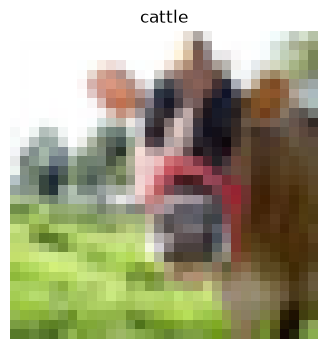

In [6]:
import matplotlib.pyplot as plt

# 取出第一張圖片
image, label = train_dataset[0]

print("Image size:", image.size)
print("Label ID:", label)
print("Class name:", train_dataset.classes[label])

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

In [7]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\project\MMIP\week4")
DATA_DIR = PROJECT_DIR / "data"

IMDB_DIR = DATA_DIR / "IMDb"
CIFAR_DIR = DATA_DIR / "CIFAR100"
FLICKR_DIR = DATA_DIR / "Flickr30k"

for folder in [IMDB_DIR, CIFAR_DIR, FLICKR_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
    print("Created:", folder)

Created: D:\project\MMIP\week4\data\IMDb
Created: D:\project\MMIP\week4\data\CIFAR100
Created: D:\project\MMIP\week4\data\Flickr30k


In [8]:
import os
from pathlib import Path

FLICKR_DIR = Path(r"D:\project\MMIP\week4\data\Flickr30k")
CACHE_DIR = FLICKR_DIR / "cache"

FLICKR_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Hugging Face 快取放在 D 槽
os.environ["HF_HOME"] = str(CACHE_DIR)
os.environ["HF_HUB_CACHE"] = str(CACHE_DIR / "hub")

print("下載位置:", FLICKR_DIR)
print("快取位置:", CACHE_DIR)

下載位置: D:\project\MMIP\week4\data\Flickr30k
快取位置: D:\project\MMIP\week4\data\Flickr30k\cache


In [9]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="nlphuji/flickr30k",
    repo_type="dataset",
    local_dir=str(FLICKR_DIR),
    max_workers=4
)

print("下載完成！")
print("資料集位置:", dataset_path)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

flickr30k.py: 0.00B [00:00, ?B/s]

README.md:   0%|          | 0.00/641 [00:00<?, ?B/s]

flickr30k-images.zip:   0%|          | 0.00/4.39G [00:00<?, ?B/s]

flickr_annotations_30k.csv:   0%|          | 0.00/12.9M [00:00<?, ?B/s]

.gitattributes: 0.00B [00:00, ?B/s]

下載完成！
資料集位置: D:\project\MMIP\week4\data\Flickr30k


### Sentiment Analysis — IMDb Dataset

IMDb 是電影評論情緒分類資料集，包含 50,000 筆有標籤評論。

- Training：25,000 筆
- Testing：25,000 筆
- Positive：正面評論（Label = 1）
- Negative：負面評論（Label = 0）

本作業使用 IMDb 資料集，準備後續 RNN 與 LSTM 情緒分類模型的訓練與測試資料。

In [10]:
from pathlib import Path
import pandas as pd

IMDB_DIR = Path(r"D:\project\MMIP\week4\data\IMDb\aclImdb")

def load_imdb(split):
    data = []

    for sentiment, label in [("pos", 1), ("neg", 0)]:
        folder = IMDB_DIR / split / sentiment

        for file in sorted(folder.glob("*.txt")):
            text = file.read_text(encoding="utf-8")
            data.append({
                "text": text,
                "label": label
            })

    return pd.DataFrame(data)

train_df = load_imdb("train")
test_df = load_imdb("test")

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting label distribution:")
print(test_df["label"].value_counts().sort_index())

Training samples: 25000
Testing samples: 25000

Training label distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Testing label distribution:
label
0    12500
1    12500
Name: count, dtype: int64


In [11]:
print("=== Positive Review ===")
print(train_df[train_df["label"] == 1].iloc[0]["text"][:600])

print("\n=== Negative Review ===")
print(train_df[train_df["label"] == 0].iloc[0]["text"][:600])

=== Positive Review ===
Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, the insightful students who can see right through their pathetic teachers' pomp, the pettiness of the whole situation, all remind me of the schools I knew and their students. When I saw the episode in which a student repeatedly tried to burn down the school, I immediately recalled ......... at .......... High

=== Negative Review ===
Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob by the crazy chantings of it's singers. Unfortunately it stays absurd the WHOLE time with no general narrative eventually making it just too off putting. 

### Image Captioning — Flickr30k Dataset

Flickr30k 是影像描述資料集，包含圖片及對應的英文文字描述。

- Dataset：Flickr30k
- Source：Hugging Face（nlphuji/flickr30k）
- Number of samples：31,014（此版本）
- Captions：每張圖片對應 5 段文字描述
- Task：Image Captioning

本作業使用 Flickr30k 準備圖片與文字描述配對資料，供 Quiz 4 的 Image Captioning 模型使用。

In [12]:
from pathlib import Path
from collections import Counter

FLICKR_DIR = Path(r"D:\project\MMIP\week4\data\Flickr30k")

files = [p for p in FLICKR_DIR.rglob("*") if p.is_file()]

print("Total files:", len(files))

extensions = Counter(p.suffix.lower() for p in files)

print("\nFile types:")
for ext, count in extensions.most_common():
    print(f"{ext or '(no extension)'}: {count}")

print("\nFirst 20 files:")
for p in files[:20]:
    print(p.relative_to(FLICKR_DIR))

Total files: 13

File types:
.metadata: 5
(no extension): 3
.zip: 1
.py: 1
.csv: 1
.md: 1
.log: 1

First 20 files:
.gitattributes
flickr30k-images.zip
flickr30k.py
flickr_annotations_30k.csv
README.md
.cache\huggingface\.gitignore
.cache\huggingface\download\.gitattributes.metadata
.cache\huggingface\download\flickr30k-images.zip.metadata
.cache\huggingface\download\flickr30k.py.metadata
.cache\huggingface\download\flickr_annotations_30k.csv.metadata
.cache\huggingface\download\README.md.metadata
cache\hub\datasets--nlphuji--flickr30k\refs\main
cache\xet\logs\xet_20261010T012124942+0800_15072.log


In [15]:
from pathlib import Path
import pandas as pd
import zipfile

FLICKR_DIR = Path(r"D:\project\MMIP\week4\data\Flickr30k")

zip_path = FLICKR_DIR / "flickr30k-images.zip"
csv_path = FLICKR_DIR / "flickr_annotations_30k.csv"

# 讀取文字描述
df = pd.read_csv(csv_path)

print("=== CSV 資料 ===")
print("資料筆數:", len(df))
print("欄位名稱:", df.columns.tolist())
display(df.head())

# 檢查 ZIP 裡面的圖片
with zipfile.ZipFile(zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("\n=== ZIP 圖片資料 ===")
    print("圖片數量:", len(image_files))
    print("前 5 個圖片路徑:")
    for name in image_files[:5]:
        print(name)

=== CSV 資料 ===
資料筆數: 31014
欄位名稱: ['raw', 'sentids', 'split', 'filename', 'img_id']


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2
3,"[""Someone in a blue shirt and hat is standing ...","[15, 16, 17, 18, 19]",train,1000344755.jpg,3
4,"[""Two men, one in a gray shirt, one in a black...","[20, 21, 22, 23, 24]",train,1000366164.jpg,4



=== ZIP 圖片資料 ===
圖片數量: 63566
前 5 個圖片路徑:
flickr30k-images/2609797461.jpg
__MACOSX/flickr30k-images/._2609797461.jpg
flickr30k-images/1788892671.jpg
__MACOSX/flickr30k-images/._1788892671.jpg
flickr30k-images/129860826.jpg


In [16]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
        and not name.startswith("__MACOSX/")
        and not name.split("/")[-1].startswith("._")
    ]

print("真正的圖片數量:", len(image_files))
print("CSV 資料筆數:", len(df))
print("CSV 欄位:", df.columns.tolist())

真正的圖片數量: 31783
CSV 資料筆數: 31014
CSV 欄位: ['raw', 'sentids', 'split', 'filename', 'img_id']


In [18]:
print("CSV 欄位名稱：")
print(df.columns.tolist())

print("\n前 3 筆資料：")
display(df.head(3))

CSV 欄位名稱：
['raw', 'sentids', 'split', 'filename', 'img_id']

前 3 筆資料：


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2


In [19]:
from pathlib import Path
import pandas as pd
import ast
import io
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

# Flickr30k 資料夾
FLICKR_DIR = Path(r"D:\project\MMIP\week4\data\Flickr30k")

csv_path = FLICKR_DIR / "flickr_annotations_30k.csv"
zip_path = FLICKR_DIR / "flickr30k-images.zip"

# 重新讀取 CSV
flickr_df = pd.read_csv(csv_path)

# 移除欄位名稱前後可能存在的空白
flickr_df.columns = flickr_df.columns.str.strip()

print("Flickr30k 欄位:", flickr_df.columns.tolist())
print("資料筆數:", len(flickr_df))

display(flickr_df.head(3))

Flickr30k 欄位: ['raw', 'sentids', 'split', 'filename', 'img_id']
資料筆數: 31014


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2


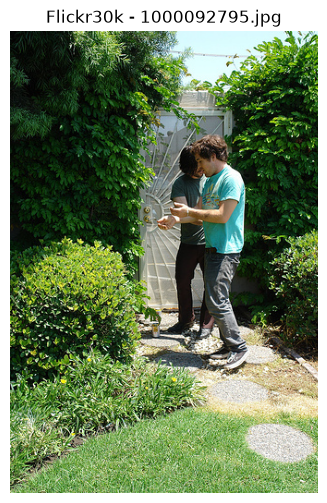

=== Image Captions ===
1. Two young guys with shaggy hair look at their hands while hanging out in the yard.
2. Two young, White males are outside near many bushes.
3. Two men in green shirts are standing in a yard.
4. A man in a blue shirt standing in a garden.
5. Two friends enjoy time spent together.


In [22]:
import ast
import io
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

# 選擇第一筆資料
sample = flickr_df.iloc[0]

# 取得圖片檔名
filename = sample["filename"]

# 取得五段文字描述（正確欄位是 raw）
captions = sample["raw"]

# 將字串轉成 Python List
if isinstance(captions, str):
    captions = ast.literal_eval(captions)

# ZIP 裡面的圖片路徑
image_path = f"flickr30k-images/{filename}"

# 從 ZIP 讀取圖片
with zipfile.ZipFile(zip_path, "r") as z:
    image_data = z.read(image_path)

image = Image.open(io.BytesIO(image_data)).convert("RGB")

# 顯示圖片
plt.figure(figsize=(9, 6))
plt.imshow(image)
plt.title(f"Flickr30k - {filename}")
plt.axis("off")
plt.show()

# 顯示對應的五段描述
print("=== Image Captions ===")

for i, caption in enumerate(captions, 1):
    print(f"{i}. {caption}")

In [23]:
# 計算每張圖片對應的 Caption 數量
caption_counts = flickr_df["raw"].apply(
    lambda x: len(ast.literal_eval(x)) if isinstance(x, str) else len(x)
)

print("圖片資料筆數:", len(flickr_df))
print("Caption 總數:", caption_counts.sum())

print("\n每張圖片的 Caption 數量分布:")
print(caption_counts.value_counts().sort_index())

print("\n全部圖片都有 5 段描述:", (caption_counts == 5).all())

print("\n資料集分割:")
print(flickr_df["split"].value_counts())

圖片資料筆數: 31014
Caption 總數: 155070

每張圖片的 Caption 數量分布:
raw
5    31014
Name: count, dtype: int64

全部圖片都有 5 段描述: True

資料集分割:
split
train    29000
val       1014
test      1000
Name: count, dtype: int64


### Quiz 1 — Dataset Preparation Summary

| Task | Dataset | Training | Validation | Testing |
|---|---|---:|---:|---:|
| Sentiment Analysis | IMDb | 25,000 | 待切分 | 25,000 |
| Image Classification | CIFAR-100 | 50,000 | 待切分 | 10,000 |
| Image Captioning | Flickr30k | 29,000 | 1,014 | 1,000 |

**Flickr30k Validation Results**
- Total images: 31,014
- Total captions: 155,070
- Captions per image: 5
- All images have exactly 5 captions: True

In [24]:
with zipfile.ZipFile(zip_path, "r") as z:
    zip_names = set(z.namelist())

missing_images = [
    filename
    for filename in flickr_df["filename"]
    if f"flickr30k-images/{filename}" not in zip_names
]

print("找不到對應圖片的資料筆數:", len(missing_images))
print("所有圖片配對成功:", len(missing_images) == 0)

找不到對應圖片的資料筆數: 0
所有圖片配對成功: True


## Quiz 2：Sentiment Analysis using RNN and LSTM

### 1. Dataset Preparation

使用 IMDb Large Movie Review Dataset 進行二元情緒分類。

- Positive：1
- Negative：0
- Training：20,000 筆
- Validation：5,000 筆
- Testing：25,000 筆

從原始 25,000 筆 Training Data 中切分 20% 作為 Validation Data，Testing Data 保持不變。

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

IMDB_DIR = Path(r"D:\project\MMIP\week4\data\IMDb\aclImdb")

def load_imdb(split):
    data = []

    for sentiment, label in [("pos", 1), ("neg", 0)]:
        folder = IMDB_DIR / split / sentiment

        for file in sorted(folder.glob("*.txt")):
            text = file.read_text(encoding="utf-8")
            data.append({
                "text": text,
                "label": label
            })

    return pd.DataFrame(data)

# 讀取原始資料
imdb_train_full = load_imdb("train")
imdb_test_df = load_imdb("test")

# 切分 Training / Validation
imdb_train_df, imdb_val_df = train_test_split(
    imdb_train_full,
    test_size=0.2,
    random_state=42,
    stratify=imdb_train_full["label"]
)

# 重設索引
imdb_train_df = imdb_train_df.reset_index(drop=True)
imdb_val_df = imdb_val_df.reset_index(drop=True)
imdb_test_df = imdb_test_df.reset_index(drop=True)

print("Training:", len(imdb_train_df))
print("Validation:", len(imdb_val_df))
print("Testing:", len(imdb_test_df))

print("\nTraining label distribution:")
print(imdb_train_df["label"].value_counts().sort_index())

Training: 20000
Validation: 5000
Testing: 25000

Training label distribution:
label
0    10000
1    10000
Name: count, dtype: int64


2.儲存資料集

In [2]:
SAVE_DIR = Path(r"D:\project\MMIP\week4\data\IMDb")

imdb_train_df.to_csv(SAVE_DIR / "train.csv", index=False)
imdb_val_df.to_csv(SAVE_DIR / "val.csv", index=False)
imdb_test_df.to_csv(SAVE_DIR / "test.csv", index=False)

print("IMDb 資料集儲存完成！")

IMDb 資料集儲存完成！


3.文字前處理

3-1. 先建立 Tokenizer

### 2. Text Preprocessing

將 IMDb 電影評論轉成模型可以處理的數字序列。

處理步驟：
1. 將英文轉成小寫
2. 移除 HTML 標籤
3. 使用正規表示式進行 Tokenization
4. 建立 Vocabulary
5. 將文字轉成 Token IDs

In [4]:
import re
from collections import Counter

def tokenize(text):
    # 移除 HTML 標籤
    text = re.sub(r"<[^>]+>", " ", str(text))

    # 轉小寫
    text = text.lower()

    # 只保留英文字母與單字中的撇號
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)

    return tokens

# 測試 Tokenizer
sample_text = imdb_train_df.iloc[0]["text"]

tokens = tokenize(sample_text)

print("Original text:")
print(sample_text[:300])

print("\nTokens:")
print(tokens[:50])

print("\nNumber of tokens:", len(tokens))

Original text:
Many reviews I've read reveals that most people tend to like Part One better than Part Two. I feel exactly the opposite. Part One played around a bit much with trying to find different ways of showing Che Guevara's personality through different types of film stock, different locations, and cutting b

Tokens:
['many', 'reviews', "i've", 'read', 'reveals', 'that', 'most', 'people', 'tend', 'to', 'like', 'part', 'one', 'better', 'than', 'part', 'two', 'i', 'feel', 'exactly', 'the', 'opposite', 'part', 'one', 'played', 'around', 'a', 'bit', 'much', 'with', 'trying', 'to', 'find', 'different', 'ways', 'of', 'showing', 'che', "guevara's", 'personality', 'through', 'different', 'types', 'of', 'film', 'stock', 'different', 'locations', 'and', 'cutting']

Number of tokens: 443


3-2. 建立 Vocabulary

In [5]:
word_counter = Counter()

for text in imdb_train_df["text"]:
    word_counter.update(tokenize(text))

# 只保留最常出現的 20,000 個單字
MAX_VOCAB_SIZE = 20000

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in word_counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Most common words:")
print(word_counter.most_common(10))

Vocabulary size: 20000
Most common words:
[('the', 269791), ('and', 131163), ('a', 130252), ('of', 116877), ('to', 108228), ('is', 85861), ('in', 75288), ('it', 63418), ('i', 61616), ('this', 60747)]


第四步：將文字轉換成 Token ID

### 3. Text Encoding

將每篇電影評論轉換成固定長度的 Token ID 序列。

- Vocabulary Size：20,000
- Maximum Sequence Length：256
- Padding Token：0
- Unknown Token：1

使用固定長度序列，方便後續 RNN 與 LSTM 進行 Batch Training。

In [6]:
MAX_LEN = 256

def encode_text(text):
    tokens = tokenize(text)

    # 將單字轉換成 Token ID
    token_ids = [vocab.get(word, 1) for word in tokens]

    # 截取前 256 個 Token
    token_ids = token_ids[:MAX_LEN]

    # 不足 256 個則補 0
    if len(token_ids) < MAX_LEN:
        token_ids += [0] * (MAX_LEN - len(token_ids))

    return token_ids

# 測試第一篇評論
sample_text = imdb_train_df.iloc[0]["text"]
encoded = encode_text(sample_text)

print("Original tokens:", tokenize(sample_text)[:20])
print("Encoded IDs:", encoded[:20])
print("Sequence length:", len(encoded))
print("Padding count:", encoded.count(0))

Original tokens: ['many', 'reviews', "i've", 'read', 'reveals', 'that', 'most', 'people', 'tend', 'to', 'like', 'part', 'one', 'better', 'than', 'part', 'two', 'i', 'feel', 'exactly']
Encoded IDs: [107, 840, 205, 329, 2778, 12, 88, 78, 2423, 6, 36, 169, 28, 128, 72, 169, 104, 10, 231, 605]
Sequence length: 256
Padding count: 0


第五步：建立 PyTorch Dataset 與 DataLoader

In [7]:
import torch
from torch.utils.data import Dataset, DataLoader

class IMDbDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["label"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        token_ids = encode_text(self.texts[idx])

        return (
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32)
        )

train_dataset = IMDbDataset(imdb_train_df)
val_dataset = IMDbDataset(imdb_val_df)
test_dataset = IMDbDataset(imdb_test_df)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# 測試一個 Batch
images_or_texts, labels = next(iter(train_loader))

print("\nInput shape:", images_or_texts.shape)
print("Label shape:", labels.shape)
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

Training batches: 625
Validation batches: 157
Testing batches: 782

Input shape: torch.Size([32, 256])
Label shape: torch.Size([32])
Device: cuda


第六步：建立 RNN 模型

### 4. Simple RNN Model

使用 PyTorch 建立 Simple RNN 進行情緒二元分類。

模型架構：
- Embedding Dimension：128
- RNN Hidden Size：128
- RNN Layers：1
- Output：1（Binary Classification）
- Loss Function：BCEWithLogitsLoss
- Optimizer：Adam

In [8]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # 計算每篇評論的有效 Token 數量
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()

        # [batch, 256] -> [batch, 256, 128]
        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        # 取得最後的 Hidden State
        _, hidden = self.rnn(packed)

        # [1, batch, 128] -> [batch, 128]
        last_hidden = hidden[-1]

        # [batch, 128] -> [batch]
        logits = self.fc(last_hidden).squeeze(1)

        return logits


rnn_model = SentimentRNN(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(rnn_model)

total_params = sum(p.numel() for p in rnn_model.parameters())
print(f"\nTotal parameters: {total_params:,}")
print("Device:", device)

SentimentRNN(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Total parameters: 2,593,153
Device: cuda


第七步：先測試 Forward Pass

In [9]:
# 取得一個 Batch
inputs, labels = next(iter(train_loader))

# 搬到 GPU
inputs = inputs.to(device)
labels = labels.to(device)

# 測試模型
rnn_model.eval()

with torch.no_grad():
    outputs = rnn_model(inputs)

print("Input shape:", inputs.shape)
print("Output shape:", outputs.shape)
print("Label shape:", labels.shape)

print("\nFirst 5 logits:")
print(outputs[:5])

print("\nFirst 5 probabilities:")
print(torch.sigmoid(outputs[:5]))

Input shape: torch.Size([32, 256])
Output shape: torch.Size([32])
Label shape: torch.Size([32])

First 5 logits:
tensor([ 0.6374, -0.1174, -0.0758, -0.1736,  0.1313], device='cuda:0')

First 5 probabilities:
tensor([0.6542, 0.4707, 0.4811, 0.4567, 0.5328], device='cuda:0')


第八步：建立 Training Loop

### 5. RNN Model Training

使用 IMDb Training Dataset 訓練 Simple RNN。

- Epochs：5
- Batch Size：32
- Learning Rate：0.001
- Optimizer：Adam
- Loss Function：BCEWithLogitsLoss

每個 Epoch 計算 Training Loss、Training Accuracy、Validation Loss 與 Validation Accuracy。

使用 Validation Loss 選擇最佳模型。

In [10]:
import time
import copy
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    rnn_model.parameters(),
    lr=0.001
)

EPOCHS = 5

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_state = None

for epoch in range(EPOCHS):

    start_time = time.time()

    # ===== Training =====
    rnn_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = rnn_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        # 避免 RNN Gradient Exploding
        torch.nn.utils.clip_grad_norm_(
            rnn_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_acc = train_correct / train_total

    # ===== Validation =====
    rnn_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = rnn_model(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    # ===== Record History =====
    history["train_loss"].append(avg_train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(avg_val_loss)
    history["val_acc"].append(val_acc)

    # ===== Save Best Model =====
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        best_model_state = copy.deepcopy(
            rnn_model.state_dict()
        )

        torch.save(
            best_model_state,
            "rnn_best.pth"
        )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed:.1f}s",
        flush=True
    )

print("\nRNN Training Completed!")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Epoch 1/5 | Train Loss: 0.6703 | Train Acc: 0.5891 | Val Loss: 0.6456 | Val Acc: 0.6228 | Time: 10.2s
Epoch 2/5 | Train Loss: 0.6000 | Train Acc: 0.6884 | Val Loss: 0.6023 | Val Acc: 0.6890 | Time: 9.4s
Epoch 3/5 | Train Loss: 0.5302 | Train Acc: 0.7440 | Val Loss: 0.5551 | Val Acc: 0.7338 | Time: 9.7s
Epoch 4/5 | Train Loss: 0.4649 | Train Acc: 0.7891 | Val Loss: 0.5883 | Val Acc: 0.6956 | Time: 9.6s
Epoch 5/5 | Train Loss: 0.4045 | Train Acc: 0.8265 | Val Loss: 0.5719 | Val Acc: 0.7254 | Time: 9.4s

RNN Training Completed!
Best Validation Loss: 0.5551


第九步：繪製 Loss 與 Accuracy 曲線

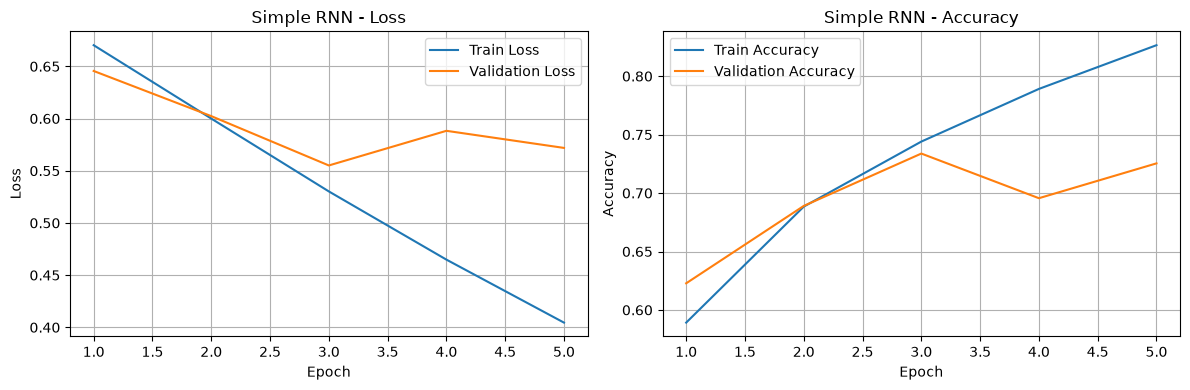

In [11]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

# Loss
plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Simple RNN - Loss")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)

plt.plot(epochs_range, history["train_acc"], label="Train Accuracy")
plt.plot(epochs_range, history["val_acc"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Simple RNN - Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 6. RNN Model Evaluation

載入 Validation Loss 最低的 RNN 模型，使用 IMDb Test Dataset 評估分類表現。

Evaluation Metrics:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

=== Simple RNN Test Results ===
Accuracy : 0.7332
Precision: 0.7332
Recall   : 0.7334
F1-score : 0.7333

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.73      0.73     12500
    Positive       0.73      0.73      0.73     12500

    accuracy                           0.73     25000
   macro avg       0.73      0.73      0.73     25000
weighted avg       0.73      0.73      0.73     25000



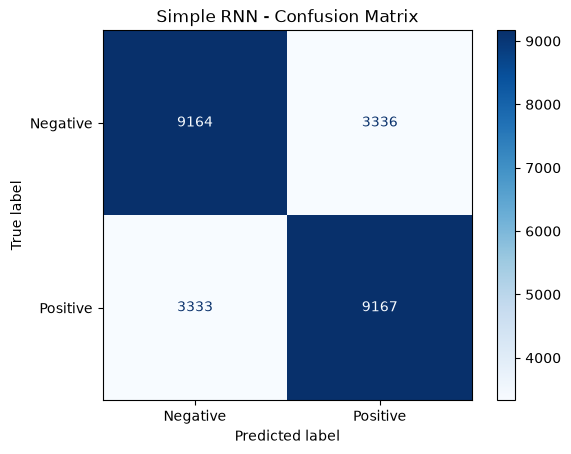

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 載入最佳 RNN 模型
rnn_model.load_state_dict(
    torch.load(
        "rnn_best.pth",
        map_location=device,
        weights_only=True
    )
)

rnn_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = rnn_model(inputs)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).long()

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

# 計算指標
rnn_test_acc = accuracy_score(all_labels, all_predictions)
rnn_test_precision = precision_score(all_labels, all_predictions)
rnn_test_recall = recall_score(all_labels, all_predictions)
rnn_test_f1 = f1_score(all_labels, all_predictions)

print("=== Simple RNN Test Results ===")
print(f"Accuracy : {rnn_test_acc:.4f}")
print(f"Precision: {rnn_test_precision:.4f}")
print(f"Recall   : {rnn_test_recall:.4f}")
print(f"F1-score : {rnn_test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"]
    )
)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Simple RNN - Confusion Matrix")
plt.show()

第十二步：建立 LSTM 模型

### 7. LSTM Model

使用 LSTM 取代 Simple RNN，進行情緒二元分類。

模型設定：
- Embedding Dimension：128
- LSTM Hidden Size：128
- LSTM Layers：1
- Output：1
- Loss Function：BCEWithLogitsLoss
- Optimizer：Adam

使用與 Simple RNN 相同的資料集、Vocabulary、Batch Size 和訓練 Epoch 數量，以比較兩種模型的分類效果。

In [13]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()

        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        # LSTM 回傳 hidden state 和 cell state
        _, (hidden, cell) = self.lstm(packed)

        last_hidden = hidden[-1]

        logits = self.fc(last_hidden).squeeze(1)

        return logits


lstm_model = SentimentLSTM(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128
).to(device)

print(lstm_model)

total_params = sum(p.numel() for p in lstm_model.parameters())

print(f"\nTotal parameters: {total_params:,}")
print("Device:", device)

SentimentLSTM(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)

Total parameters: 2,692,225
Device: cuda


第十三步：訓練 LSTM

In [14]:
lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

LSTM_EPOCHS = 5

lstm_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_lstm_val_loss = float("inf")

for epoch in range(LSTM_EPOCHS):

    start_time = time.time()

    # ===== Training =====
    lstm_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        lstm_optimizer.zero_grad()

        outputs = lstm_model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        lstm_optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_acc = train_correct / train_total

    # ===== Validation =====
    lstm_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = lstm_model(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    lstm_history["train_loss"].append(avg_train_loss)
    lstm_history["train_acc"].append(train_acc)
    lstm_history["val_loss"].append(avg_val_loss)
    lstm_history["val_acc"].append(val_acc)

    # 儲存最佳模型
    if avg_val_loss < best_lstm_val_loss:

        best_lstm_val_loss = avg_val_loss

        torch.save(
            lstm_model.state_dict(),
            "lstm_best.pth"
        )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/{LSTM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Time: {elapsed:.1f}s",
        flush=True
    )

print("\nLSTM Training Completed!")
print(f"Best Validation Loss: {best_lstm_val_loss:.4f}")

Epoch 1/5 | Train Loss: 0.6309 | Train Acc: 0.6477 | Val Loss: 0.5619 | Val Acc: 0.7370 | Time: 10.7s
Epoch 2/5 | Train Loss: 0.4733 | Train Acc: 0.7857 | Val Loss: 0.4384 | Val Acc: 0.8070 | Time: 10.1s
Epoch 3/5 | Train Loss: 0.3457 | Train Acc: 0.8598 | Val Loss: 0.4222 | Val Acc: 0.8034 | Time: 9.9s
Epoch 4/5 | Train Loss: 0.2576 | Train Acc: 0.8989 | Val Loss: 0.4347 | Val Acc: 0.8102 | Time: 9.7s
Epoch 5/5 | Train Loss: 0.1788 | Train Acc: 0.9334 | Val Loss: 0.4162 | Val Acc: 0.8404 | Time: 10.0s

LSTM Training Completed!
Best Validation Loss: 0.4162


第十四步：比較 RNN 與 LSTM 訓練曲線

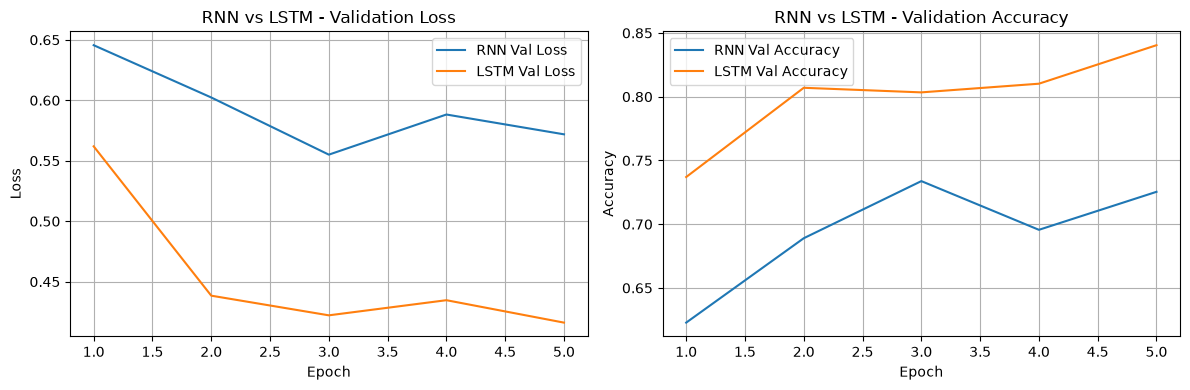

In [15]:
epochs_range = range(1, 6)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["val_loss"], label="RNN Val Loss")
plt.plot(epochs_range, lstm_history["val_loss"], label="LSTM Val Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN vs LSTM - Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(epochs_range, history["val_acc"], label="RNN Val Accuracy")
plt.plot(epochs_range, lstm_history["val_acc"], label="LSTM Val Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN vs LSTM - Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

第十五步：測試 LSTM 模型

### 8. LSTM Model Evaluation

載入 Validation Loss 最低的 LSTM 模型，使用與 Simple RNN 相同的 IMDb Test Dataset 評估 Accuracy、Precision、Recall 和 F1-score。

=== LSTM Test Results ===
Accuracy : 0.8328
Precision: 0.8502
Recall   : 0.8079
F1-score : 0.8285

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.86      0.84     12500
    Positive       0.85      0.81      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



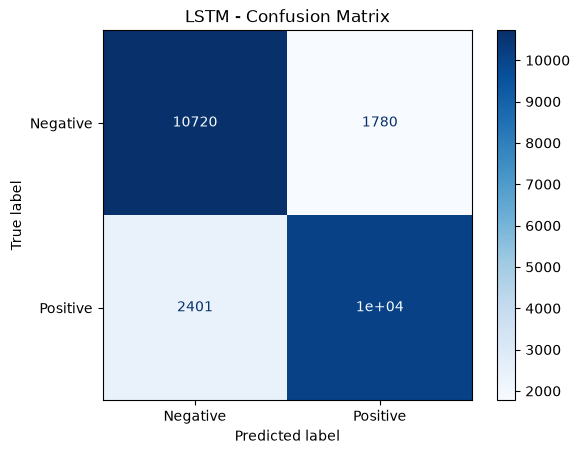

In [16]:
# 載入最佳 LSTM 模型
lstm_model.load_state_dict(
    torch.load(
        "lstm_best.pth",
        map_location=device,
        weights_only=True
    )
)

lstm_model.eval()

lstm_labels = []
lstm_predictions = []

with torch.no_grad():
    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = lstm_model(inputs)

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).long()

        lstm_labels.extend(labels.numpy().tolist())
        lstm_predictions.extend(predictions.cpu().numpy().tolist())

# 計算評估指標
lstm_test_acc = accuracy_score(lstm_labels, lstm_predictions)
lstm_test_precision = precision_score(lstm_labels, lstm_predictions)
lstm_test_recall = recall_score(lstm_labels, lstm_predictions)
lstm_test_f1 = f1_score(lstm_labels, lstm_predictions)

print("=== LSTM Test Results ===")
print(f"Accuracy : {lstm_test_acc:.4f}")
print(f"Precision: {lstm_test_precision:.4f}")
print(f"Recall   : {lstm_test_recall:.4f}")
print(f"F1-score : {lstm_test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        lstm_labels,
        lstm_predictions,
        target_names=["Negative", "Positive"]
    )
)

# Confusion Matrix
cm = confusion_matrix(lstm_labels, lstm_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("LSTM - Confusion Matrix")
plt.show()

第十六步：建立 RNN vs LSTM 最終比較表

In [17]:
comparison_df = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM"],
    "Accuracy": [rnn_test_acc, lstm_test_acc],
    "Precision": [rnn_test_precision, lstm_test_precision],
    "Recall": [rnn_test_recall, lstm_test_recall],
    "F1-score": [rnn_test_f1, lstm_test_f1]
})

display(comparison_df.round(4))

print(
    f"\nLSTM Accuracy improvement: "
    f"{(lstm_test_acc - rnn_test_acc) * 100:+.2f} percentage points"
)

,Model,Accuracy,Precision,Recall,F1-score
0,Simple RNN,0.7332,0.7332,0.7334,0.7333
1,LSTM,0.8328,0.8502,0.8079,0.8285



LSTM Accuracy improvement: +9.95 percentage points


### 9. Conclusion — RNN vs LSTM

本實驗使用 IMDb Large Movie Review Dataset 進行情緒二元分類，並比較 Simple RNN 與 LSTM 的分類效果。

兩個模型皆使用相同的 Training、Validation、Testing Dataset，以及相同的 Vocabulary Size（20,000）、Sequence Length（256）、Embedding Dimension（128）、Hidden Size（128）、Batch Size（32）與 Epochs（5）。

#### Experimental Results

| Metric | Simple RNN | LSTM |
|---|---:|---:|
| Accuracy | 0.7332 | 0.8328 |
| Precision | 0.7332 | 0.8502 |
| Recall | 0.7334 | 0.8079 |
| F1-score | 0.7333 | 0.8285 |

#### Observations

1. LSTM 的 Test Accuracy 達到 83.28%，高於 Simple RNN 的 73.32%，提升約 9.96 個百分點。
2. Simple RNN 在 Epoch 3 取得最佳 Validation Loss，之後出現 Overfitting。
3. LSTM 在 Epoch 5 取得最低 Validation Loss，且 Validation Accuracy 整體優於 Simple RNN。
4. LSTM 使用 Cell State 與 Gates 控制資訊傳遞，較能保留長距離序列資訊，有助於理解較長的電影評論。
5. LSTM 的參數量較多，但在本次實驗中獲得更好的分類效果。

#### Conclusion

本實驗結果顯示，在 IMDb 情緒分類任務中，LSTM 的分類準確率、Precision、Recall 與 F1-score 均優於 Simple RNN。

LSTM 能透過門控機制改善序列資訊的保留能力，因此在處理較長的文字評論時，具有較好的分類表現。

然而，本實驗僅比較單次訓練結果，尚不能證明 LSTM 在所有資料集與設定下都優於 Simple RNN。

## Quiz 3：Image Classification using ViT and ResNet

### 1. Dataset Preparation

使用 CIFAR-100 進行 100 類影像分類。

- Original Training Images：50,000
- Training Images：45,000
- Validation Images：5,000
- Testing Images：10,000
- Number of Classes：100
- Original Image Size：32 × 32 × 3

使用 Stratified Split，確保每個類別在 Training 和 Validation Dataset 中維持相同的比例。

In [18]:
from pathlib import Path
import numpy as np
import torch
from torchvision.datasets import CIFAR100
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

CIFAR_DIR = Path(r"D:\project\MMIP\week4\data\CIFAR100")

# 載入已下載的 CIFAR-100
cifar_train_full = CIFAR100(
    root=str(CIFAR_DIR),
    train=True,
    download=False
)

cifar_test_dataset = CIFAR100(
    root=str(CIFAR_DIR),
    train=False,
    download=False
)

# 取得標籤
cifar_labels = np.array(cifar_train_full.targets)

# Stratified Split
train_indices, val_indices = train_test_split(
    np.arange(len(cifar_train_full)),
    test_size=0.1,
    random_state=42,
    stratify=cifar_labels
)

cifar_train_subset = Subset(cifar_train_full, train_indices)
cifar_val_subset = Subset(cifar_train_full, val_indices)

print("Training:", len(cifar_train_subset))
print("Validation:", len(cifar_val_subset))
print("Testing:", len(cifar_test_dataset))
print("Number of classes:", len(cifar_train_full.classes))

print("\nFirst 10 classes:")
print(cifar_train_full.classes[:10])

Training: 45000
Validation: 5000
Testing: 10000
Number of classes: 100

First 10 classes:
['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']


### 2. Image Preprocessing

將 CIFAR-100 影像調整成預訓練模型需要的輸入格式。

- Original Image Size：32 × 32
- Resized Image Size：224 × 224
- Normalization：ImageNet Mean / Standard Deviation
- Batch Size：16

Training Dataset 使用基本的 Data Augmentation，Validation 和 Testing Dataset 不使用隨機增強。

In [19]:
from torchvision import transforms
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader, Subset

# ImageNet normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training：加入 Data Augmentation
cifar_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Validation / Testing：不使用隨機增強
cifar_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# 分別建立 Dataset，避免共用 transform
cifar_train_base = CIFAR100(
    root=str(CIFAR_DIR),
    train=True,
    download=False,
    transform=cifar_train_transform
)

cifar_val_base = CIFAR100(
    root=str(CIFAR_DIR),
    train=True,
    download=False,
    transform=cifar_eval_transform
)

cifar_test_base = CIFAR100(
    root=str(CIFAR_DIR),
    train=False,
    download=False,
    transform=cifar_eval_transform
)

# 使用前一步的切分索引
cifar_train_dataset = Subset(cifar_train_base, train_indices)
cifar_val_dataset = Subset(cifar_val_base, val_indices)
cifar_test_dataset = cifar_test_base

# DataLoader
CIFAR_BATCH_SIZE = 16

cifar_train_loader = DataLoader(
    cifar_train_dataset,
    batch_size=CIFAR_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

cifar_val_loader = DataLoader(
    cifar_val_dataset,
    batch_size=CIFAR_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

cifar_test_loader = DataLoader(
    cifar_test_dataset,
    batch_size=CIFAR_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(cifar_train_loader))
print("Validation batches:", len(cifar_val_loader))
print("Testing batches:", len(cifar_test_loader))

Training batches: 2813
Validation batches: 313
Testing batches: 625


In [20]:
cifar_images, cifar_labels_batch = next(iter(cifar_train_loader))

print("Image batch shape:", cifar_images.shape)
print("Label batch shape:", cifar_labels_batch.shape)
print("Image dtype:", cifar_images.dtype)
print("Label range:", cifar_labels_batch.min().item(),
      "~", cifar_labels_batch.max().item())

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32
Label range: 7 ~ 98


### 3. Vision Transformer (ViT)

使用預訓練的 ViT-Base 模型進行 CIFAR-100 影像分類。

- Pretrained Model：google/vit-base-patch16-224-in21k
- Input Size：224 × 224
- Patch Size：16 × 16
- Hidden Dimension：768
- Transformer Layers：12
- Number of Classes：100

為了降低 GPU 記憶體需求，初期先凍結 ViT Backbone，只訓練新的 Classification Head。

In [21]:
import torch
from transformers import ViTForImageClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "google/vit-base-patch16-224-in21k"

vit_model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=100,
    ignore_mismatched_sizes=True
)

# 凍結預訓練 Backbone
for param in vit_model.vit.parameters():
    param.requires_grad = False

# Classification Head 保持可訓練
for param in vit_model.classifier.parameters():
    param.requires_grad = True

vit_model = vit_model.to(device)

total_params = sum(p.numel() for p in vit_model.parameters())
trainable_params = sum(
    p.numel() for p in vit_model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--google--vit-base-patch16-224-in21k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Device: cuda
Total parameters: 85,875,556
Trainable parameters: 76,900
Frozen parameters: 85,798,656


In [22]:
vit_model.eval()

# 先用 2 張圖片測試，避免一次佔用太多 GPU 記憶體
sample_images = cifar_images[:2].to(device)

with torch.no_grad():
    outputs = vit_model(pixel_values=sample_images)
    logits = outputs.logits

print("Input shape:", sample_images.shape)
print("Output shape:", logits.shape)

print("Predicted class IDs:", logits.argmax(dim=1).cpu().tolist())

if torch.cuda.is_available():
    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 100])
Predicted class IDs: [53, 29]
GPU memory allocated: 0.43 GB


### 4. ViT Fine-tuning

為了降低 GPU 記憶體需求，使用 Partial Fine-tuning：

- Freeze：Patch Embedding 與前 10 層 Transformer
- Fine-tune：最後 2 層 Transformer
- Train：Classification Head
- Number of Classes：100

使用 CrossEntropyLoss 進行多類別分類。

In [23]:
# 先凍結整個 ViT Backbone
for param in vit_model.vit.parameters():
    param.requires_grad = False

# 解凍最後兩層 Transformer
for layer in vit_model.vit.encoder.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Classification Head 保持可訓練
for param in vit_model.classifier.parameters():
    param.requires_grad = True

# 統計參數
total_params = sum(p.numel() for p in vit_model.parameters())

trainable_params = sum(
    p.numel()
    for p in vit_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

print("\nTrainable Transformer Layers:")

for i, layer in enumerate(vit_model.vit.encoder.layer):
    if any(p.requires_grad for p in layer.parameters()):
        print(f"Layer {i}: Trainable")

Total parameters: 85,875,556
Trainable parameters: 14,252,644
Frozen parameters: 71,622,912

Trainable Transformer Layers:
Layer 10: Trainable
Layer 11: Trainable


In [24]:
import torch.nn as nn

criterion_vit = nn.CrossEntropyLoss()

vit_model.train()

# 只取兩張影像測試
sample_images = cifar_images[:2].to(device)
sample_labels = cifar_labels_batch[:2].to(device)

vit_model.zero_grad(set_to_none=True)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# Forward
outputs = vit_model(pixel_values=sample_images)
loss = criterion_vit(outputs.logits, sample_labels)

# Backward
loss.backward()

print("Test Loss:", round(loss.item(), 4))
print("Backward Pass: Success")

if torch.cuda.is_available():
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

# 清除測試梯度
vit_model.zero_grad(set_to_none=True)

Test Loss: 4.6085
Backward Pass: Success
Peak GPU memory: 0.49 GB


### 5. ViT Training Configuration

使用 Partial Fine-tuning 訓練 ViT-Base。

- Fine-tuning Layers：Transformer Layer 10–11
- Classification Head：Trainable
- Batch Size：8
- Epochs：5
- Backbone Learning Rate：1e-5
- Classifier Learning Rate：1e-4
- Optimizer：AdamW
- Loss Function：CrossEntropyLoss

使用 Validation Accuracy 選擇最佳模型。

In [25]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

VIT_BATCH_SIZE = 8
VIT_EPOCHS = 5

vit_train_loader = DataLoader(
    cifar_train_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

vit_val_loader = DataLoader(
    cifar_val_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

vit_criterion = nn.CrossEntropyLoss()

vit_optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in vit_model.vit.parameters()
                if p.requires_grad
            ],
            "lr": 1e-5
        },
        {
            "params": vit_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=0.01
)

print("Training batches:", len(vit_train_loader))
print("Validation batches:", len(vit_val_loader))
print("Trainable parameters:",
      sum(p.numel() for p in vit_model.parameters() if p.requires_grad))

Training batches: 5625
Validation batches: 625
Trainable parameters: 14252644


In [26]:
vit_model.train()

images, labels = next(iter(vit_train_loader))
images = images.to(device)
labels = labels.to(device)

vit_optimizer.zero_grad(set_to_none=True)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

outputs = vit_model(pixel_values=images)
loss = vit_criterion(outputs.logits, labels)

loss.backward()

torch.nn.utils.clip_grad_norm_(
    [p for p in vit_model.parameters() if p.requires_grad],
    max_norm=1.0
)

vit_optimizer.step()

print("Batch Size:", images.shape[0])
print("Training Step Loss:", round(loss.item(), 4))
print("Optimizer Step: Success")

if torch.cuda.is_available():
    print(
        "Peak GPU Memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

vit_optimizer.zero_grad(set_to_none=True)

Batch Size: 8
Training Step Loss: 4.5698
Optimizer Step: Success
Peak GPU Memory: 0.64 GB


### 6. ViT Fine-tuning Results

使用 CIFAR-100 Training Dataset 進行 ViT Fine-tuning。

- Training Samples：45,000
- Validation Samples：5,000
- Epochs：5
- Batch Size：8
- Optimizer：AdamW
- Loss Function：CrossEntropyLoss
- Best Model：vit_best.pth

記錄 Training / Validation Loss、Top-1 Accuracy、Top-5 Accuracy 和 Training Time。

In [27]:
import time
import torch
from tqdm.auto import tqdm

def run_vit_epoch(model, loader, criterion, device, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct1 = 0
    total_correct5 = 0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Train" if is_train else "Validation",
        leave=False
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            outputs = model(pixel_values=images)
            logits = outputs.logits

            loss = criterion(logits, labels)

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    max_norm=1.0
                )

                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # Top-1 Accuracy
        predictions = logits.argmax(dim=1)
        total_correct1 += (
            predictions == labels
        ).sum().item()

        # Top-5 Accuracy
        top5_predictions = logits.topk(5, dim=1).indices
        total_correct5 += (
            top5_predictions == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            acc=f"{total_correct1 / total_samples:.4f}"
        )

    return {
        "loss": total_loss / total_samples,
        "top1": total_correct1 / total_samples,
        "top5": total_correct5 / total_samples
    }

In [28]:
from pathlib import Path

vit_history = []
vit_best_val_acc = 0.0

VIT_SAVE_PATH = Path("vit_best.pth")

for epoch in range(VIT_EPOCHS):

    start_time = time.time()

    print(f"\nEpoch {epoch + 1}/{VIT_EPOCHS}")

    # Training
    train_metrics = run_vit_epoch(
        vit_model,
        vit_train_loader,
        vit_criterion,
        device,
        optimizer=vit_optimizer
    )

    # Validation
    val_metrics = run_vit_epoch(
        vit_model,
        vit_val_loader,
        vit_criterion,
        device
    )

    elapsed = time.time() - start_time

    vit_history.append({
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["top1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["top1"],
        "val_top5": val_metrics["top5"],
        "time": elapsed
    })

    print(
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['top1']:.4f}"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['top1']:.4f} | "
        f"Val Top-5: {val_metrics['top5']:.4f}"
    )

    print(f"Time: {elapsed:.1f} seconds")

    # Save best model
    if val_metrics["top1"] > vit_best_val_acc:
        vit_best_val_acc = val_metrics["top1"]

        torch.save(
            vit_model.state_dict(),
            VIT_SAVE_PATH
        )

        print(f"Best model saved! Val Acc: {vit_best_val_acc:.4f}")

print("\nViT Fine-tuning Completed!")


Epoch 1/5


Train:   0%|          | 0/5625 [00:00<?, ?it/s]

Validation:   0%|          | 0/625 [00:00<?, ?it/s]

Train Loss: 2.2199 | Train Acc: 0.6646
Val Loss: 1.0162 | Val Acc: 0.7588 | Val Top-5: 0.9338
Time: 644.0 seconds
Best model saved! Val Acc: 0.7588

Epoch 2/5


Train:   0%|          | 0/5625 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/625 [00:00<?, ?it/s]

Train Loss: 0.5418 | Train Acc: 0.8464
Val Loss: 0.6739 | Val Acc: 0.8098 | Val Top-5: 0.9606
Time: 666.9 seconds
Best model saved! Val Acc: 0.8098

Epoch 5/5


Train:   0%|          | 0/5625 [00:00<?, ?it/s]

Validation:   0%|          | 0/625 [00:00<?, ?it/s]

Train Loss: 0.4631 | Train Acc: 0.8676
Val Loss: 0.6582 | Val Acc: 0.8148 | Val Top-5: 0.9624
Time: 667.3 seconds
Best model saved! Val Acc: 0.8148

ViT Fine-tuning Completed!


In [29]:
import pandas as pd

vit_results_df = pd.DataFrame(vit_history)

display(vit_results_df.round(4))

print(f"\nBest Validation Accuracy: {vit_best_val_acc:.4f}")
print(f"Total Training Time: {vit_results_df['time'].sum():.1f} seconds")

,epoch,train_loss,train_acc,val_loss,val_acc,val_top5,time
0,1,2.2199,0.6646,1.0162,0.7588,0.9338,644.0487
1,2,0.8177,0.7882,0.7709,0.7892,0.9502,649.8987
2,3,0.6396,0.8223,0.7001,0.8022,0.9578,665.2402
3,4,0.5418,0.8464,0.6739,0.8098,0.9606,666.9282
4,5,0.4631,0.8676,0.6582,0.8148,0.9624,667.2890



Best Validation Accuracy: 0.8148
Total Training Time: 3293.4 seconds


### 7. ViT Test Evaluation

使用最佳 Validation Accuracy 對應的 ViT 權重，
在 CIFAR-100 Test Dataset 上進行最終評估。

Evaluation Metrics:
- Test Loss
- Top-1 Accuracy
- Top-5 Accuracy
- Macro-AUC (One-vs-Rest)

In [30]:
# 載入 Validation Accuracy 最佳的模型
vit_model.load_state_dict(
    torch.load(
        "vit_best.pth",
        map_location=device,
        weights_only=True
    )
)

vit_model.eval()

print("Best ViT model loaded successfully!")
print("Device:", device)

Best ViT model loaded successfully!
Device: cuda


In [31]:
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

vit_test_loader = DataLoader(
    cifar_test_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

vit_model.eval()

all_labels = []
all_probs = []

total_loss = 0.0
total_samples = 0
correct_top1 = 0
correct_top5 = 0

with torch.inference_mode():
    for images, labels in tqdm(vit_test_loader, desc="ViT Testing"):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = vit_model(pixel_values=images)
        logits = outputs.logits

        loss = F.cross_entropy(logits, labels)

        probs = F.softmax(logits, dim=1)

        batch_size = labels.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size

        # Top-1
        predictions = logits.argmax(dim=1)
        correct_top1 += (predictions == labels).sum().item()

        # Top-5
        top5 = logits.topk(5, dim=1).indices
        correct_top5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        all_labels.append(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

# 合併所有 Batch
vit_y_true = np.concatenate(all_labels)
vit_y_prob = np.concatenate(all_probs)

# Metrics
vit_test_loss = total_loss / total_samples
vit_test_acc = correct_top1 / total_samples
vit_test_top5 = correct_top5 / total_samples

vit_test_auc = roc_auc_score(
    vit_y_true,
    vit_y_prob,
    labels=np.arange(100),
    multi_class="ovr",
    average="macro"
)

print("\n===== ViT Test Results =====")
print(f"Test Loss:       {vit_test_loss:.4f}")
print(f"Top-1 Accuracy:  {vit_test_acc:.4f}")
print(f"Top-5 Accuracy:  {vit_test_top5:.4f}")
print(f"Macro-AUC:       {vit_test_auc:.4f}")

ViT Testing:   0%|          | 0/1250 [00:00<?, ?it/s]


===== ViT Test Results =====
Test Loss:       0.6396
Top-1 Accuracy:  0.8204
Top-5 Accuracy:  0.9624
Macro-AUC:       0.9963


### 8. ResNet-18 Fine-tuning

使用 ImageNet 預訓練的 ResNet-18 進行 CIFAR-100 影像分類。

- Model：ResNet-18
- Pretrained Weights：ImageNet-1K
- Input Size：224 × 224
- Output Classes：100
- Fine-tuning：最後一個 Residual Stage（layer4）與 Fully Connected Layer

使用與 ViT 相同的 Training、Validation 和 Testing Dataset。

In [32]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# 載入 ImageNet 預訓練權重
resnet_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# 修改分類層：1000 類 -> 100 類
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    100
)

# 先凍結全部參數
for param in resnet_model.parameters():
    param.requires_grad = False

# 解凍最後一個 Residual Stage
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

# 解凍分類層
for param in resnet_model.fc.parameters():
    param.requires_grad = True

resnet_model = resnet_model.to(device)

# 統計參數
resnet_total_params = sum(
    p.numel() for p in resnet_model.parameters()
)

resnet_trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total Parameters: {resnet_total_params:,}")
print(f"Trainable Parameters: {resnet_trainable_params:,}")
print(f"Frozen Parameters: {resnet_total_params - resnet_trainable_params:,}")

print("\nClassifier:")
print(resnet_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\user/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:04<00:00, 10.8MB/s]


Device: cuda
Total Parameters: 11,227,812
Trainable Parameters: 8,445,028
Frozen Parameters: 2,782,784

Classifier:
Linear(in_features=512, out_features=100, bias=True)


In [33]:
resnet_model.eval()

images, labels = next(iter(cifar_train_loader))

sample_images = images[:8].to(device)

with torch.no_grad():
    outputs = resnet_model(sample_images)

print("Input Shape:", sample_images.shape)
print("Output Shape:", outputs.shape)

if torch.cuda.is_available():
    print(
        "GPU Memory Allocated:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

Input Shape: torch.Size([8, 3, 224, 224])
Output Shape: torch.Size([8, 100])
GPU Memory Allocated: 0.63 GB


### 9. ResNet-18 Training Configuration

使用 ImageNet 預訓練的 ResNet-18 進行 Partial Fine-tuning。

- Training Samples：45,000
- Validation Samples：5,000
- Batch Size：32
- Epochs：5
- Trainable Layers：layer4 and fc
- Optimizer：AdamW
- Loss Function：CrossEntropyLoss
- Model Selection：Best Validation Accuracy

In [34]:
from torch.utils.data import DataLoader
import torch.nn as nn

RESNET_BATCH_SIZE = 32
RESNET_EPOCHS = 5

resnet_train_loader = DataLoader(
    cifar_train_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

resnet_val_loader = DataLoader(
    cifar_val_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

resnet_test_loader = DataLoader(
    cifar_test_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.AdamW(
    [
        {
            "params": resnet_model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=0.01
)

print("Training batches:", len(resnet_train_loader))
print("Validation batches:", len(resnet_val_loader))
print("Testing batches:", len(resnet_test_loader))

Training batches: 1407
Validation batches: 157
Testing batches: 313


In [35]:
def set_resnet_train_mode(model):
    model.train()

    # 凍結的部分維持 Evaluation Mode
    model.conv1.eval()
    model.bn1.eval()
    model.relu.eval()
    model.maxpool.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    # 允許最後一個 Stage 與分類層訓練
    model.layer4.train()
    model.fc.train()


set_resnet_train_mode(resnet_model)

images, labels = next(iter(resnet_train_loader))

images = images.to(device)
labels = labels.to(device)

resnet_optimizer.zero_grad(set_to_none=True)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

# Forward
logits = resnet_model(images)
loss = resnet_criterion(logits, labels)

# Backward
loss.backward()

# Gradient Clipping
torch.nn.utils.clip_grad_norm_(
    [p for p in resnet_model.parameters() if p.requires_grad],
    max_norm=1.0
)

# Optimizer Step
resnet_optimizer.step()

print("Batch Size:", images.shape[0])
print("Training Step Loss:", round(loss.item(), 4))
print("Optimizer Step: Success")

if torch.cuda.is_available():
    print(
        "Peak GPU Memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

resnet_optimizer.zero_grad(set_to_none=True)

Batch Size: 32
Training Step Loss: 4.8317
Optimizer Step: Success
Peak GPU Memory: 0.86 GB


### 10. ResNet-18 Training

使用 Partial Fine-tuning 訓練 ResNet-18。

- Frozen Layers：conv1, bn1, layer1, layer2, layer3
- Trainable Layers：layer4, fc
- Epochs：5
- Batch Size：32
- Optimizer：AdamW
- Best Model：resnet_best.pth

每個 Epoch 記錄 Training Loss、Training Accuracy、Validation Loss、Validation Accuracy、Validation Top-5 Accuracy 與 Training Time。

In [36]:
import time
import torch
from tqdm.auto import tqdm

def run_resnet_epoch(model, loader, criterion, device, optimizer=None):

    is_train = optimizer is not None

    if is_train:
        set_resnet_train_mode(model)
    else:
        model.eval()

    total_loss = 0.0
    total_correct1 = 0
    total_correct5 = 0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Train" if is_train else "Validation",
        leave=False
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    max_norm=1.0
                )

                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # Top-1 Accuracy
        predictions = logits.argmax(dim=1)
        total_correct1 += (predictions == labels).sum().item()

        # Top-5 Accuracy
        top5_predictions = logits.topk(5, dim=1).indices
        total_correct5 += (
            top5_predictions == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        progress.set_postfix(
            loss=f"{total_loss / total_samples:.4f}",
            acc=f"{total_correct1 / total_samples:.4f}"
        )

    return {
        "loss": total_loss / total_samples,
        "top1": total_correct1 / total_samples,
        "top5": total_correct5 / total_samples
    }

In [37]:
from pathlib import Path

resnet_history = []
resnet_best_val_acc = -1.0

RESNET_SAVE_PATH = Path("resnet_best.pth")

for epoch in range(RESNET_EPOCHS):

    start_time = time.time()

    print(f"\nEpoch {epoch + 1}/{RESNET_EPOCHS}")

    # Training
    train_metrics = run_resnet_epoch(
        resnet_model,
        resnet_train_loader,
        resnet_criterion,
        device,
        optimizer=resnet_optimizer
    )

    # Validation
    val_metrics = run_resnet_epoch(
        resnet_model,
        resnet_val_loader,
        resnet_criterion,
        device
    )

    elapsed = time.time() - start_time

    resnet_history.append({
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["top1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["top1"],
        "val_top5": val_metrics["top5"],
        "time": elapsed
    })

    print(
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['top1']:.4f}"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['top1']:.4f} | "
        f"Val Top-5: {val_metrics['top5']:.4f}"
    )

    print(f"Time: {elapsed:.1f} seconds")

    # Save Best Model
    if val_metrics["top1"] > resnet_best_val_acc:

        resnet_best_val_acc = val_metrics["top1"]

        torch.save(
            resnet_model.state_dict(),
            RESNET_SAVE_PATH
        )

        print(
            f"Best model saved! "
            f"Val Acc: {resnet_best_val_acc:.4f}"
        )

print("\nResNet-18 Fine-tuning Completed!")


Epoch 1/5


Train:   0%|          | 0/1407 [00:00<?, ?it/s]

Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Train Loss: 2.5677 | Train Acc: 0.4470
Val Loss: 1.4574 | Val Acc: 0.6394 | Val Top-5: 0.9042
Time: 97.6 seconds
Best model saved! Val Acc: 0.6394

Epoch 2/5


Train:   0%|          | 0/1407 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Train Loss: 0.8201 | Train Acc: 0.7706
Val Loss: 0.8730 | Val Acc: 0.7432 | Val Top-5: 0.9500
Time: 97.2 seconds
Best model saved! Val Acc: 0.7432

Epoch 5/5


Train:   0%|          | 0/1407 [00:00<?, ?it/s]

Validation:   0%|          | 0/157 [00:00<?, ?it/s]

Train Loss: 0.7040 | Train Acc: 0.8000
Val Loss: 0.8217 | Val Acc: 0.7552 | Val Top-5: 0.9528
Time: 97.3 seconds
Best model saved! Val Acc: 0.7552

ResNet-18 Fine-tuning Completed!


In [38]:
import pandas as pd

resnet_results_df = pd.DataFrame(resnet_history)

display(resnet_results_df.round(4))

print(f"\nBest Validation Accuracy: {resnet_best_val_acc:.4f}")
print(
    f"Total Training Time: "
    f"{resnet_results_df['time'].sum():.1f} seconds"
)

,epoch,train_loss,train_acc,val_loss,val_acc,val_top5,time
0,1,2.5677,0.4470,1.4574,0.6394,0.9042,97.6487
1,2,1.2682,0.6754,1.0752,0.6974,0.9334,97.6797
2,3,0.9771,0.7333,0.9450,0.7244,0.9458,97.8198
3,4,0.8201,0.7706,0.8730,0.7432,0.9500,97.2311
4,5,0.7040,0.8000,0.8217,0.7552,0.9528,97.2938



Best Validation Accuracy: 0.7552
Total Training Time: 487.7 seconds


### 11. ResNet-18 Test Evaluation

載入 Validation Accuracy 最佳的 ResNet-18 權重，在 CIFAR-100 Test Dataset 上進行評估。

Evaluation Metrics:
- Test Loss
- Top-1 Accuracy
- Top-5 Accuracy
- Macro-AUC (One-vs-Rest)

最後與 ViT 的測試結果進行比較。

In [39]:
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

# 載入最佳 ResNet 模型
resnet_model.load_state_dict(
    torch.load(
        "resnet_best.pth",
        map_location=device,
        weights_only=True
    )
)

resnet_model.eval()

resnet_all_labels = []
resnet_all_probs = []

total_loss = 0.0
total_samples = 0
correct_top1 = 0
correct_top5 = 0

with torch.inference_mode():

    for images, labels in tqdm(
        resnet_test_loader,
        desc="ResNet Testing"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Forward
        logits = resnet_model(images)

        # Loss
        loss = F.cross_entropy(logits, labels)

        # Probability
        probs = F.softmax(logits, dim=1)

        batch_size = labels.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size

        # Top-1 Accuracy
        predictions = logits.argmax(dim=1)
        correct_top1 += (
            predictions == labels
        ).sum().item()

        # Top-5 Accuracy
        top5 = logits.topk(5, dim=1).indices

        correct_top5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        resnet_all_labels.append(
            labels.cpu().numpy()
        )

        resnet_all_probs.append(
            probs.cpu().numpy()
        )

# 合併所有 Batch
resnet_y_true = np.concatenate(resnet_all_labels)
resnet_y_prob = np.concatenate(resnet_all_probs)

# 計算指標
resnet_test_loss = total_loss / total_samples
resnet_test_acc = correct_top1 / total_samples
resnet_test_top5 = correct_top5 / total_samples

resnet_test_auc = roc_auc_score(
    resnet_y_true,
    resnet_y_prob,
    labels=np.arange(100),
    multi_class="ovr",
    average="macro"
)

print("\n===== ResNet-18 Test Results =====")
print(f"Test Loss:       {resnet_test_loss:.4f}")
print(f"Top-1 Accuracy:  {resnet_test_acc:.4f}")
print(f"Top-5 Accuracy:  {resnet_test_top5:.4f}")
print(f"Macro-AUC:       {resnet_test_auc:.4f}")

ResNet Testing:   0%|          | 0/313 [00:00<?, ?it/s]


===== ResNet-18 Test Results =====
Test Loss:       0.8182
Top-1 Accuracy:  0.7579
Top-5 Accuracy:  0.9534
Macro-AUC:       0.9950


In [40]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["ViT-Base", "ResNet-18"],
    "Test Loss": [
        vit_test_loss,
        resnet_test_loss
    ],
    "Top-1 Accuracy": [
        vit_test_acc,
        resnet_test_acc
    ],
    "Top-5 Accuracy": [
        vit_test_top5,
        resnet_test_top5
    ],
    "Macro-AUC": [
        vit_test_auc,
        resnet_test_auc
    ],
    "Training Time (s)": [
        vit_results_df["time"].sum(),
        resnet_results_df["time"].sum()
    ]
})

display(comparison_df.round(4))

,Model,Test Loss,Top-1 Accuracy,Top-5 Accuracy,Macro-AUC,Training Time (s)
0,ViT-Base,0.6396,0.8204,0.9624,0.9963,3293.4049
1,ResNet-18,0.8182,0.7579,0.9534,0.9950,487.6731


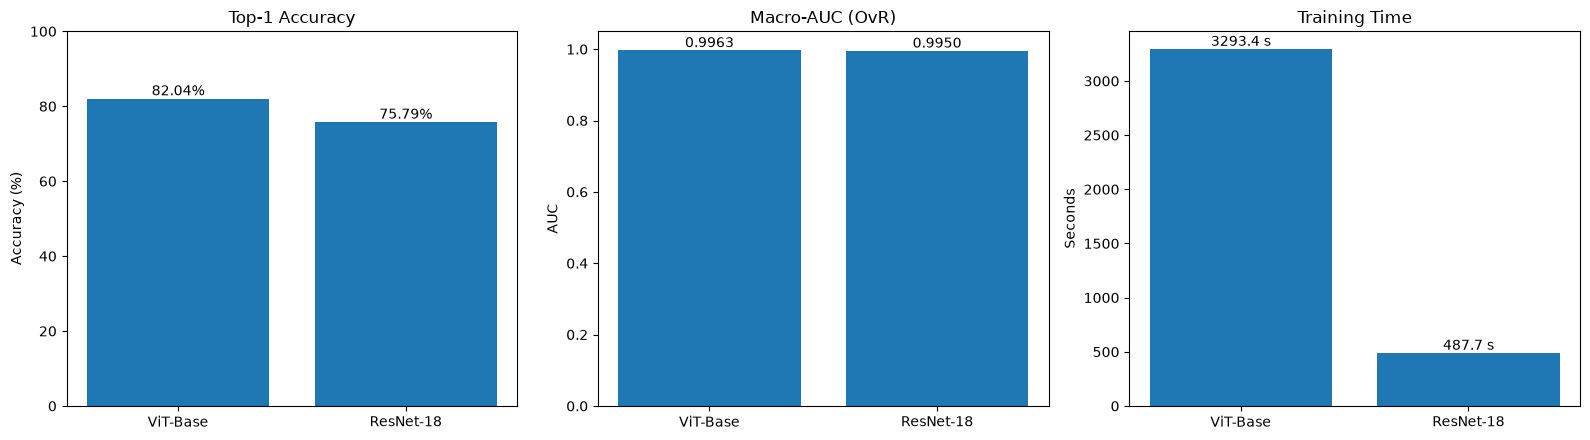

In [41]:
import matplotlib.pyplot as plt
import numpy as np

models = ["ViT-Base", "ResNet-18"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Top-1 Accuracy
bars = axes[0].bar(
    models,
    [vit_test_acc * 100, resnet_test_acc * 100]
)
axes[0].set_title("Top-1 Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)
axes[0].bar_label(bars, fmt="%.2f%%")

# Macro-AUC
bars = axes[1].bar(
    models,
    [vit_test_auc, resnet_test_auc]
)
axes[1].set_title("Macro-AUC (OvR)")
axes[1].set_ylabel("AUC")
axes[1].set_ylim(0, 1.05)
axes[1].bar_label(bars, fmt="%.4f")

# Training Time
bars = axes[2].bar(
    models,
    [
        vit_results_df["time"].sum(),
        resnet_results_df["time"].sum()
    ]
)
axes[2].set_title("Training Time")
axes[2].set_ylabel("Seconds")
axes[2].bar_label(bars, fmt="%.1f s")

plt.tight_layout()
plt.show()

### 12. Conclusion

本次實驗使用 CIFAR-100 Dataset 進行 100 類影像分類，
比較 Vision Transformer (ViT-Base) 與 ResNet-18 的 Fine-tuning 效果。

兩個模型皆使用預訓練權重，並採用 Partial Fine-tuning：

- ViT-Base：訓練最後兩層 Transformer Encoder 與 Classification Head。
- ResNet-18：訓練最後一個 Residual Stage (layer4) 與 Fully Connected Layer。

兩個模型皆訓練 5 個 Epoch，並使用相同的資料切分進行評估。

#### Experimental Results

| Metric | ViT-Base | ResNet-18 |
|---|---:|---:|
| Test Loss | 0.6396 | 0.8182 |
| Top-1 Accuracy | 82.04% | 75.79% |
| Top-5 Accuracy | 96.24% | 95.34% |
| Macro-AUC | 0.9963 | 0.9950 |
| Training Time (s) | 3293.4 | 487.7 |

#### Discussion

1. ViT-Base 的 Top-1 Accuracy 為 82.04%，比 ResNet-18 的 75.79% 高出 6.25 個百分點，顯示 ViT 在本次實驗中具有較好的分類準確率。

2. ViT-Base 的 Macro-AUC 為 0.9963，ResNet-18 為 0.9950，兩者皆具有良好的多類別區分能力，且 ViT 略高。

3. ResNet-18 的訓練時間約為 487.7 秒，明顯短於 ViT-Base 的 3293.4 秒，顯示 ResNet-18 在本次硬體與訓練設定下具有較低的訓練成本。

4. 由於兩個模型的架構、Batch Size、預訓練資料與 Fine-tuning 設定不同，實驗結果不能完全歸因於 Transformer 與 CNN 架構的差異。

#### Conclusion

本次實驗中，ViT-Base 取得較高的分類準確率與 Macro-AUC，而 ResNet-18 則具有較短的訓練時間。

因此，若以分類準確率為主要考量，ViT-Base 是較好的選擇；若更重視訓練時間與計算資源，ResNet-18 則具有優勢。

## Quiz 4：Image Captioning

### 1. Dataset Preparation

使用 Flickr30k Dataset 進行 Image Captioning。

- Dataset：Flickr30k
- Annotated Images：31,014
- Captions per Image：5
- Language：English
- Task：Generate captions from images

使用預訓練 Image Captioning 模型產生描述，並透過 Gemini、BLEU 與 BERTScore 進行評估。

In [43]:
from pathlib import Path
import pandas as pd
import zipfile

FLICKR_DIR = Path(r"D:\project\MMIP\week4\data\Flickr30k")

ANNOTATION_PATH = FLICKR_DIR / "flickr_annotations_30k.csv"
IMAGE_ZIP_PATH = FLICKR_DIR / "flickr30k-images.zip"

print("Annotation exists:", ANNOTATION_PATH.exists())
print("Image ZIP exists:", IMAGE_ZIP_PATH.exists())

# 讀取標註
flickr_df = pd.read_csv(ANNOTATION_PATH)

print("\nDataset Shape:", flickr_df.shape)
print("\nColumns:", flickr_df.columns.tolist())

print("\nDataset Split:")
print(flickr_df["split"].value_counts())

display(flickr_df.head(3))

Annotation exists: True
Image ZIP exists: True

Dataset Shape: (31014, 5)

Columns: ['raw', 'sentids', 'split', 'filename', 'img_id']

Dataset Split:
split
train    29000
val       1014
test      1000
Name: count, dtype: int64


,raw,sentids,split,filename,img_id
0,"[""Two young guys with shaggy hair look at thei...","[0, 1, 2, 3, 4]",train,1000092795.jpg,0
1,"[""Several men in hard hats are operating a gia...","[5, 6, 7, 8, 9]",train,10002456.jpg,1
2,"[""A child in a pink dress is climbing up a set...","[10, 11, 12, 13, 14]",train,1000268201.jpg,2


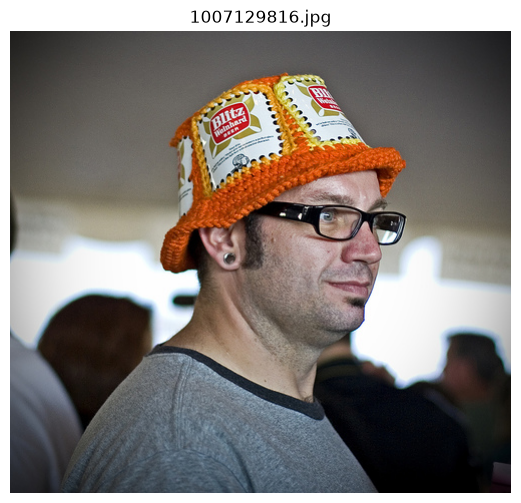

Ground Truth Captions:

1. The man with pierced ears is wearing glasses and an orange hat.
2. A man with glasses is wearing a beer can crocheted hat.
3. A man with gauges and glasses is wearing a Blitz hat.
4. A man in an orange hat starring at something.
5. A man wears an orange hat and glasses.


In [44]:
import ast
import io
import matplotlib.pyplot as plt
from PIL import Image

# 先選擇 Test Dataset 的第一張圖片
sample_row = flickr_df[
    flickr_df["split"] == "test"
].iloc[0]

filename = sample_row["filename"]

# CSV 中的 raw 欄位存放 5 段描述
captions = ast.literal_eval(sample_row["raw"])

# 從 ZIP 讀取圖片
with zipfile.ZipFile(IMAGE_ZIP_PATH, "r") as zf:
    image_bytes = zf.read(
        f"flickr30k-images/{filename}"
    )

image = Image.open(
    io.BytesIO(image_bytes)
).convert("RGB")

# 顯示圖片
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(filename)
plt.show()

# 顯示 Ground Truth Captions
print("Ground Truth Captions:\n")

for i, caption in enumerate(captions, 1):
    print(f"{i}. {caption}")

### 2. BLIP Image Captioning

使用預訓練的 BLIP 模型進行 Image Captioning。

- Model：Salesforce/blip-image-captioning-base
- Input：RGB Image
- Output：English Caption
- Device：CUDA (RTX 2060)
- Generation：Unconditional Image Captioning

使用 Flickr30k Test Dataset 的圖片進行測試。

In [45]:
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration

BLIP_MODEL_NAME = "Salesforce/blip-image-captioning-base"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# 載入 Image Processor + Tokenizer
blip_processor = BlipProcessor.from_pretrained(
    BLIP_MODEL_NAME
)

# 載入預訓練 BLIP 模型
blip_model = BlipForConditionalGeneration.from_pretrained(
    BLIP_MODEL_NAME
)

blip_model = blip_model.to(device)
blip_model.eval()

print("BLIP Model Loaded Successfully!")

Device: cuda


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

BLIP Model Loaded Successfully!


In [46]:
import time

# 將 PIL Image 轉成模型輸入
inputs = blip_processor(
    images=image,
    return_tensors="pt"
).to(device)

# 計算生成時間
if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.time()

with torch.inference_mode():
    generated_ids = blip_model.generate(
        **inputs,
        max_new_tokens=50,
        num_beams=5
    )

if device.type == "cuda":
    torch.cuda.synchronize()

generation_time = time.time() - start_time

# Token IDs 轉回英文
generated_caption = blip_processor.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Image:", filename)
print("Generated Caption:", generated_caption)
print(f"Generation Time: {generation_time:.3f} seconds")

print("\nGround Truth Captions:")
for i, caption in enumerate(captions, 1):
    print(f"{i}. {caption}")

Image: 1007129816.jpg
Generated Caption: the man is wearing a hat
Generation Time: 0.658 seconds

Ground Truth Captions:
1. The man with pierced ears is wearing glasses and an orange hat.
2. A man with glasses is wearing a beer can crocheted hat.
3. A man with gauges and glasses is wearing a Blitz hat.
4. A man in an orange hat starring at something.
5. A man wears an orange hat and glasses.


### 3. BLIP Fine-tuning Preparation

使用 Flickr30k Dataset Fine-tune 預訓練的 BLIP 模型。

- Dataset：Flickr30k
- Training Split：train
- Validation Split：val
- Model：Salesforce/blip-image-captioning-base
- Frozen：Vision Encoder and most Text Decoder layers
- Trainable：Last 2 Text Decoder layers and output head
- Batch Size：2
- Objective：Caption Generation using Cross-Entropy Loss

In [47]:
print("Vision Encoder:")
print(type(blip_model.vision_model).__name__)

print("\nText Decoder:")
print(type(blip_model.text_decoder).__name__)

print("\nDecoder Layers:")
print(len(blip_model.text_decoder.bert.encoder.layer))

print("\nText Output Head:")
print(blip_model.text_decoder.cls)

print("\nTotal Parameters:")
print(f"{sum(p.numel() for p in blip_model.parameters()):,}")

print("\nGPU:")
print(torch.cuda.get_device_name(0))

Vision Encoder:
BlipVisionModel

Text Decoder:
BlipTextLMHeadModel

Decoder Layers:
12

Text Output Head:
BlipTextOnlyMLMHead(
  (predictions): BlipTextLMPredictionHead(
    (transform): BlipTextPredictionHeadTransform(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (transform_act_fn): GELUActivation()
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    )
    (decoder): Linear(in_features=768, out_features=30524, bias=True)
  )
)

Total Parameters:
247,414,076

GPU:
NVIDIA GeForce RTX 2060


### 4. BLIP Partial Fine-tuning

BLIP 模型包含 Vision Encoder 與 Text Decoder。

為了降低 GPU 記憶體需求，本實驗採用 Partial Fine-tuning：

- Freeze Vision Encoder
- Freeze Text Decoder Layers 0–9
- Train Text Decoder Layers 10–11
- Train Language Model Head

透過 Flickr30k 的影像與人工描述進行監督式訓練。

In [48]:
# 先凍結所有參數
for param in blip_model.parameters():
    param.requires_grad = False

# 開放 Text Decoder 最後兩層
for param in blip_model.text_decoder.bert.encoder.layer[-2:].parameters():
    param.requires_grad = True

# 開放 Language Model Head
for param in blip_model.text_decoder.cls.parameters():
    param.requires_grad = True

# 統計參數
total_params = sum(
    p.numel() for p in blip_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in blip_model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters:    {frozen_params:,}")

print(
    f"Trainable Percentage: "
    f"{trainable_params / total_params * 100:.2f}%"
)

print("\nTrainable Parameter Names:")

for name, param in blip_model.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))

Total Parameters:     247,414,076
Trainable Parameters: 42,968,636
Frozen Parameters:    204,445,440
Trainable Percentage: 17.37%

Trainable Parameter Names:
text_decoder.bert.encoder.layer.10.attention.self.query.weight (768, 768)
text_decoder.bert.encoder.layer.10.attention.self.query.bias (768,)
text_decoder.bert.encoder.layer.10.attention.self.key.weight (768, 768)
text_decoder.bert.encoder.layer.10.attention.self.key.bias (768,)
text_decoder.bert.encoder.layer.10.attention.self.value.weight (768, 768)
text_decoder.bert.encoder.layer.10.attention.self.value.bias (768,)
text_decoder.bert.encoder.layer.10.attention.output.dense.weight (768, 768)
text_decoder.bert.encoder.layer.10.attention.output.dense.bias (768,)
text_decoder.bert.encoder.layer.10.attention.output.LayerNorm.weight (768,)
text_decoder.bert.encoder.layer.10.attention.output.LayerNorm.bias (768,)
text_decoder.bert.encoder.layer.10.crossattention.self.query.weight (768, 768)
text_decoder.bert.encoder.layer.10.crossatten

In [49]:
import ast
import io
import random
import zipfile

from torch.utils.data import Dataset
from PIL import Image


class Flickr30kCaptionDataset(Dataset):

    def __init__(
        self,
        dataframe,
        zip_path,
        processor,
        max_length=40
    ):
        self.df = dataframe.reset_index(drop=True)
        self.zip_path = zip_path
        self.processor = processor
        self.max_length = max_length
        self.zf = None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        filename = row["filename"]
        captions = ast.literal_eval(row["raw"])

        # 隨機選擇一段 Ground Truth Caption
        caption = random.choice(captions)

        # 延遲開啟 ZIP，避免每次讀取都重新建立
        if self.zf is None:
            self.zf = zipfile.ZipFile(self.zip_path, "r")

        image_bytes = self.zf.read(
            f"flickr30k-images/{filename}"
        )

        image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

        # Image + Text preprocessing
        encoding = self.processor(
            images=image,
            text=caption,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        pixel_values = encoding["pixel_values"].squeeze(0)
        input_ids = encoding["input_ids"].squeeze(0)
        attention_mask = encoding["attention_mask"].squeeze(0)

        # Padding Token 不計入 Loss
        labels = input_ids.clone()
        labels[attention_mask == 0] = -100

        return {
            "pixel_values": pixel_values,
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "labels": labels
        }

In [50]:
train_df = flickr_df[
    flickr_df["split"] == "train"
].copy()

val_df = flickr_df[
    flickr_df["split"] == "val"
].copy()

train_caption_dataset = Flickr30kCaptionDataset(
    train_df,
    IMAGE_ZIP_PATH,
    blip_processor
)

val_caption_dataset = Flickr30kCaptionDataset(
    val_df,
    IMAGE_ZIP_PATH,
    blip_processor
)

print("Training Samples:", len(train_caption_dataset))
print("Validation Samples:", len(val_caption_dataset))

sample = train_caption_dataset[0]

print("\nPixel Values:", sample["pixel_values"].shape)
print("Input IDs:", sample["input_ids"].shape)
print("Attention Mask:", sample["attention_mask"].shape)
print("Labels:", sample["labels"].shape)

print("\nDecoded Caption:")
print(
    blip_processor.tokenizer.decode(
        sample["input_ids"],
        skip_special_tokens=True
    )
)

Training Samples: 29000
Validation Samples: 1014

Pixel Values: torch.Size([3, 384, 384])
Input IDs: torch.Size([40])
Attention Mask: torch.Size([40])
Labels: torch.Size([40])

Decoded Caption:
two men in green shirts are standing in a yard.


### 5. BLIP Training Configuration

使用 Flickr30k Dataset 進行 BLIP Partial Fine-tuning。

- Training Samples：29,000
- Validation Samples：1,014
- Image Resolution：384 × 384
- Maximum Caption Length：40
- Batch Size：2
- Optimizer：AdamW
- Learning Rate：1e-5
- Loss Function：Cross-Entropy Loss

先執行單一 Batch 的 Forward 和 Backward 測試，確認 GPU 記憶體足夠。

In [51]:
from torch.utils.data import DataLoader

BLIP_BATCH_SIZE = 2

blip_train_loader = DataLoader(
    train_caption_dataset,
    batch_size=BLIP_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

blip_val_loader = DataLoader(
    val_caption_dataset,
    batch_size=BLIP_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training Batches:", len(blip_train_loader))
print("Validation Batches:", len(blip_val_loader))

batch = next(iter(blip_train_loader))

for key, value in batch.items():
    print(key, value.shape)

Training Batches: 14500
Validation Batches: 507
pixel_values torch.Size([2, 3, 384, 384])
input_ids torch.Size([2, 40])
attention_mask torch.Size([2, 40])
labels torch.Size([2, 40])


In [52]:
import torch
from torch.amp import autocast, GradScaler

# 訓練模式
blip_model.train()

# 凍結的 Vision Encoder 維持 eval
blip_model.vision_model.eval()

# 凍結的 Decoder 前 10 層維持 eval
for layer in blip_model.text_decoder.bert.encoder.layer[:-2]:
    layer.eval()

# Optimizer
blip_optimizer = torch.optim.AdamW(
    [
        p for p in blip_model.parameters()
        if p.requires_grad
    ],
    lr=1e-5,
    weight_decay=0.01
)

# Mixed Precision
blip_scaler = GradScaler("cuda")

# 單一 Batch
batch = next(iter(blip_train_loader))

pixel_values = batch["pixel_values"].to(device)
input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

blip_optimizer.zero_grad(set_to_none=True)

torch.cuda.reset_peak_memory_stats()

# Forward
with autocast("cuda", dtype=torch.float16):

    outputs = blip_model(
        pixel_values=pixel_values,
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss

print("Forward Loss:", round(loss.item(), 4))

# Backward
blip_scaler.scale(loss).backward()

# 檢查梯度，不更新模型權重
blip_scaler.unscale_(blip_optimizer)

grad_count = sum(
    p.grad is not None
    for p in blip_model.parameters()
    if p.requires_grad
)

print("Parameters with Gradients:", grad_count)
print("Backward: Success")

print(
    "Peak GPU Memory:",
    round(
        torch.cuda.max_memory_allocated() / 1024**3,
        2
    ),
    "GB"
)

# 清除梯度
blip_optimizer.zero_grad(set_to_none=True)

Forward Loss: 4.046
Parameters with Gradients: 58
Backward: Success
Peak GPU Memory: 1.87 GB


### 6. BLIP Fine-tuning Pilot Run

在正式訓練之前，先使用 100 個 Training Steps 測試：

- Training Loss
- Gradient Update
- GPU Memory Usage
- Training Time

確認訓練穩定後，再進行完整 Fine-tuning。

In [56]:
def set_blip_train_mode(model):
    model.train()

    # 凍結 Vision Encoder
    model.vision_model.eval()

    # 凍結 Decoder 前 10 層
    for layer in model.text_decoder.bert.encoder.layer[:-2]:
        layer.eval()


def prepare_blip_batch(batch, device):
    pixel_values = batch["pixel_values"].to(
        device, non_blocking=True
    )

    input_ids = batch["input_ids"].to(
        device, non_blocking=True
    )

    attention_mask = batch["attention_mask"].to(
        device, non_blocking=True
    )

    labels = batch["labels"].to(
        device, non_blocking=True
    ).clone()

    # BLIP 的第一個 Token 為起始 Token
    # 不應作為預測目標
    labels[:, 0] = -100

    return {
        "pixel_values": pixel_values,
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

In [58]:
from torch.amp import GradScaler

# 清除上次測試留下的梯度
blip_optimizer.zero_grad(set_to_none=True)

# 重新建立 GradScaler，重置內部狀態
blip_scaler = GradScaler("cuda")

print("GradScaler reset successfully!")

GradScaler reset successfully!


In [59]:
import time
import numpy as np
import torch
from tqdm.auto import tqdm
from torch.amp import autocast

PILOT_STEPS = 100

set_blip_train_mode(blip_model)

pilot_losses = []

start_time = time.time()

blip_optimizer.zero_grad(set_to_none=True)

torch.cuda.reset_peak_memory_stats()

progress = tqdm(
    blip_train_loader,
    total=PILOT_STEPS,
    desc="BLIP Pilot Training"
)

for step, batch in enumerate(progress):

    if step >= PILOT_STEPS:
        break

    batch = prepare_blip_batch(batch, device)

    with autocast("cuda", dtype=torch.float16):
        outputs = blip_model(**batch)
        loss = outputs.loss

    # 檢查 Loss
    if not torch.isfinite(loss):
        print(f"Non-finite loss at step {step + 1}")
        break

    blip_optimizer.zero_grad(set_to_none=True)

    blip_scaler.scale(loss).backward()

    blip_scaler.unscale_(blip_optimizer)

    torch.nn.utils.clip_grad_norm_(
        [p for p in blip_model.parameters() if p.requires_grad],
        max_norm=1.0
    )

    blip_scaler.step(blip_optimizer)
    blip_scaler.update()

    pilot_losses.append(loss.item())

    progress.set_postfix(
        loss=f"{loss.item():.4f}",
        avg_loss=f"{np.mean(pilot_losses):.4f}"
    )

torch.cuda.synchronize()

elapsed = time.time() - start_time

print("\n===== Pilot Training Results =====")
print("Completed Steps:", len(pilot_losses))
print("First 10 Steps Avg Loss:", round(np.mean(pilot_losses[:10]), 4))
print("Last 10 Steps Avg Loss:", round(np.mean(pilot_losses[-10:]), 4))
print("Average Loss:", round(np.mean(pilot_losses), 4))
print("Total Time:", round(elapsed, 1), "seconds")
print("Time per Step:", round(elapsed / max(len(pilot_losses), 1), 3), "seconds")
print(
    "Peak GPU Memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

BLIP Pilot Training:   0%|          | 0/100 [00:00<?, ?it/s]


===== Pilot Training Results =====
Completed Steps: 100
First 10 Steps Avg Loss: 3.3419
Last 10 Steps Avg Loss: 3.0641
Average Loss: 3.1782
Total Time: 11.6 seconds
Time per Step: 0.116 seconds
Peak GPU Memory: 2.33 GB


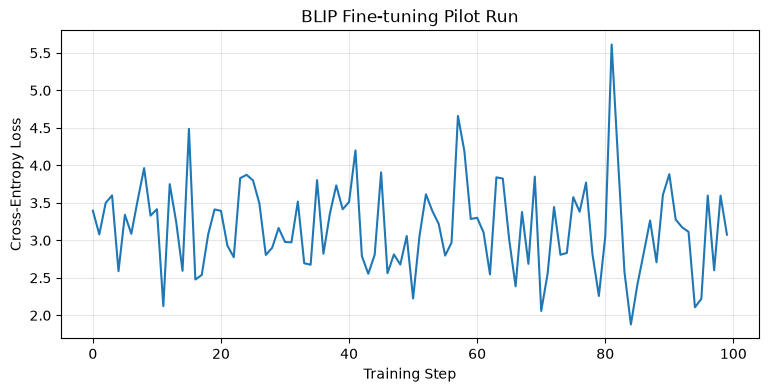

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.plot(pilot_losses)

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("BLIP Fine-tuning Pilot Run")
plt.grid(alpha=0.3)

plt.show()

In [61]:
import numpy as np

print("First 10 Steps Avg Loss:", np.mean(pilot_losses[:10]))
print("Last 10 Steps Avg Loss:", np.mean(pilot_losses[-10:]))
print("Average Loss:", np.mean(pilot_losses))

First 10 Steps Avg Loss: 3.341930603981018
Last 10 Steps Avg Loss: 3.064148187637329
Average Loss: 3.1782081627845766


In [62]:
print("Pilot Total Time:", round(elapsed, 2), "seconds")
print("Time per Step:", round(elapsed / len(pilot_losses), 3), "seconds")

time_per_step = elapsed / len(pilot_losses)

print("\nEstimated Training Time:")
print("3000 Steps:", round(3000 * time_per_step / 60, 1), "minutes")
print("1 Full Epoch:", round(14500 * time_per_step / 3600, 2), "hours")
print("3 Full Epochs:", round(43500 * time_per_step / 3600, 2), "hours")

Pilot Total Time: 11.61 seconds
Time per Step: 0.116 seconds

Estimated Training Time:
3000 Steps: 5.8 minutes
1 Full Epoch: 0.47 hours
3 Full Epochs: 1.4 hours


### 7. BLIP Fine-tuning on Flickr30k

Fine-tune BLIP on the Flickr30k training split for 3 epochs.

- Training Images: 29,000
- Validation Images: 1,014
- Batch Size: 2
- Learning Rate: 1e-5
- Optimizer: AdamW
- Mixed Precision: FP16
- Model Selection: Lowest Validation Loss

The best model checkpoint is saved for subsequent caption generation and evaluation.

In [63]:
import os
import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from torch.amp import autocast, GradScaler

# ============================
# Training Configuration
# ============================

BLIP_EPOCHS = 3

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "blip_finetuned_best.pth"

# 清除上一輪梯度
blip_optimizer.zero_grad(set_to_none=True)

# 重置 GradScaler
blip_scaler = GradScaler("cuda")

# 訓練紀錄
blip_history = []

best_val_loss = float("inf")

trainable_parameters = [
    p for p in blip_model.parameters()
    if p.requires_grad
]

training_start = time.time()

# ============================
# Training Loop
# ============================

for epoch in range(BLIP_EPOCHS):

    set_blip_train_mode(blip_model)

    train_loss_sum = 0.0

    train_bar = tqdm(
        blip_train_loader,
        desc=f"Epoch {epoch + 1}/{BLIP_EPOCHS} [Train]"
    )

    for batch in train_bar:

        batch = prepare_blip_batch(batch, device)

        blip_optimizer.zero_grad(set_to_none=True)

        with autocast("cuda", dtype=torch.float16):
            outputs = blip_model(**batch)
            loss = outputs.loss

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss: {loss.item()}"
            )

        blip_scaler.scale(loss).backward()
        blip_scaler.unscale_(blip_optimizer)

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=1.0
        )

        blip_scaler.step(blip_optimizer)
        blip_scaler.update()

        train_loss_sum += loss.item()

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = train_loss_sum / len(blip_train_loader)

    # ============================
    # Validation
    # ============================

    blip_model.eval()

    val_loss_sum = 0.0

    val_bar = tqdm(
        blip_val_loader,
        desc=f"Epoch {epoch + 1}/{BLIP_EPOCHS} [Val]"
    )

    with torch.no_grad():

        for batch in val_bar:

            batch = prepare_blip_batch(batch, device)

            with autocast("cuda", dtype=torch.float16):
                outputs = blip_model(**batch)
                loss = outputs.loss

            val_loss_sum += loss.item()

    avg_val_loss = val_loss_sum / len(blip_val_loader)

    # ============================
    # Record Results
    # ============================

    blip_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss
    })

    print(f"\nEpoch {epoch + 1}/{BLIP_EPOCHS}")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss:   {avg_val_loss:.4f}")

    # ============================
    # Save Best Model
    # ============================

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": blip_model.state_dict(),
                "optimizer_state_dict": blip_optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "history": blip_history
            },
            BEST_MODEL_PATH
        )

        print(f"Best model saved: {BEST_MODEL_PATH}")

    print("-" * 50)

# ============================
# Training Summary
# ============================

total_training_time = time.time() - training_start

blip_history_df = pd.DataFrame(blip_history)

print("\n===== BLIP Fine-tuning Completed =====")
print(blip_history_df)

print(
    f"\nTotal Training Time: "
    f"{total_training_time / 60:.2f} minutes"
)

print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Best Model Path: {BEST_MODEL_PATH}")

Epoch 1/3 [Train]:   0%|          | 0/14500 [00:00<?, ?it/s]

Epoch 1/3 [Val]:   0%|          | 0/507 [00:00<?, ?it/s]


Epoch 1/3
Train Loss: 2.2510
Val Loss:   2.2337
Best model saved: checkpoints\blip_finetuned_best.pth
--------------------------------------------------


Epoch 2/3 [Train]:   0%|          | 0/14500 [00:00<?, ?it/s]

Epoch 2/3 [Val]:   0%|          | 0/507 [00:00<?, ?it/s]


Epoch 2/3
Train Loss: 2.1446
Val Loss:   2.1805
Best model saved: checkpoints\blip_finetuned_best.pth
--------------------------------------------------


Epoch 3/3 [Train]:   0%|          | 0/14500 [00:00<?, ?it/s]

Epoch 3/3 [Val]:   0%|          | 0/507 [00:00<?, ?it/s]


Epoch 3/3
Train Loss: 2.1058
Val Loss:   2.1317
Best model saved: checkpoints\blip_finetuned_best.pth
--------------------------------------------------

===== BLIP Fine-tuning Completed =====
   epoch  train_loss  val_loss
0      1    2.251005  2.233736
1      2    2.144622  2.180479
2      3    2.105752  2.131654

Total Training Time: 83.58 minutes
Best Validation Loss: 2.1317
Best Model Path: checkpoints\blip_finetuned_best.pth


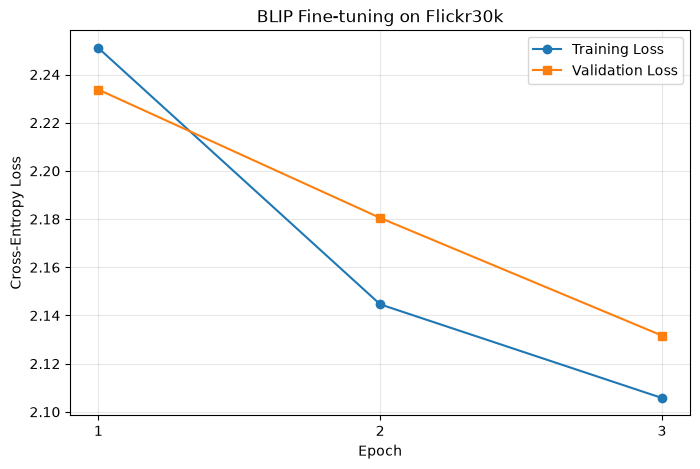

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    blip_history_df["epoch"],
    blip_history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    blip_history_df["epoch"],
    blip_history_df["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("BLIP Fine-tuning on Flickr30k")
plt.xticks(blip_history_df["epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### 8. Caption Generation After Fine-tuning

Load the best fine-tuned BLIP checkpoint and generate captions on Flickr30k test images.

Compare the generated captions with the pretrained BLIP baseline and the five ground-truth captions.

In [65]:
import torch

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

blip_model.load_state_dict(
    checkpoint["model_state_dict"]
)

blip_model.to(device)
blip_model.eval()

print("Best Checkpoint Loaded")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Loss:", checkpoint["best_val_loss"])

Best Checkpoint Loaded
Best Epoch: 3
Best Validation Loss: 2.1316538959800373


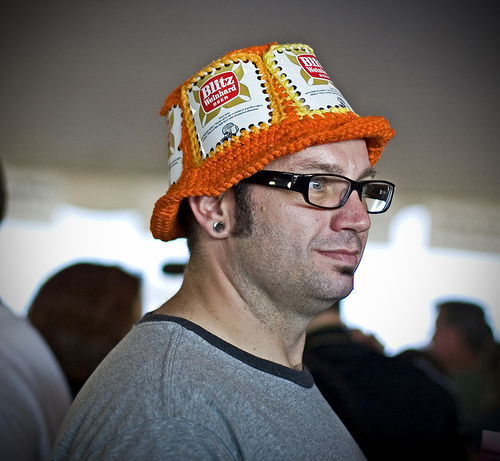

Image: 1007129816.jpg

Pretrained BLIP Caption:
the man is wearing a hat

Fine-tuned BLIP Caption:
a man wearing a hat and glasses.

Fine-tuned Generation Time: 0.319 seconds

Ground Truth Captions:
1. The man with pierced ears is wearing glasses and an orange hat.
2. A man with glasses is wearing a beer can crocheted hat.
3. A man with gauges and glasses is wearing a Blitz hat.
4. A man in an orange hat starring at something.
5. A man wears an orange hat and glasses.


In [66]:
import time
import io
import zipfile
import ast

from PIL import Image
from IPython.display import display

TEST_FILENAME = "1007129816.jpg"

test_row = flickr_df[
    (flickr_df["filename"] == TEST_FILENAME) &
    (flickr_df["split"] == "test")
].iloc[0]

ground_truths = ast.literal_eval(test_row["raw"])

with zipfile.ZipFile(IMAGE_ZIP_PATH, "r") as zf:
    image_bytes = zf.read(
        f"flickr30k-images/{TEST_FILENAME}"
    )

test_image = Image.open(
    io.BytesIO(image_bytes)
).convert("RGB")

inputs = blip_processor(
    images=test_image,
    return_tensors="pt"
).to(device)

# GPU 計時前同步
torch.cuda.synchronize()
start_time = time.perf_counter()

with torch.inference_mode():
    generated_ids = blip_model.generate(
        **inputs,
        max_new_tokens=40,
        num_beams=3
    )

torch.cuda.synchronize()
generation_time = time.perf_counter() - start_time

generated_caption = blip_processor.decode(
    generated_ids[0],
    skip_special_tokens=True
)

display(test_image)

print("Image:", TEST_FILENAME)
print("\nPretrained BLIP Caption:")
print("the man is wearing a hat")

print("\nFine-tuned BLIP Caption:")
print(generated_caption)

print(
    f"\nFine-tuned Generation Time: "
    f"{generation_time:.3f} seconds"
)

print("\nGround Truth Captions:")

for i, caption in enumerate(ground_truths, 1):
    print(f"{i}. {caption}")

### 9. BLEU Score Evaluation

Evaluate the generated captions using BLEU scores.

Each Flickr30k test image contains five human-written reference captions.

Compare the pretrained and fine-tuned BLIP models using BLEU-1 and BLEU-4.

In [67]:
%pip install nltk

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------------- ---------------------- 0.8/1.8 MB 2.0 MB/s eta 0:00:01
   ----------------------- ---------------- 1.0/1.8 MB 2.0 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 2.0 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [68]:
from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

def calculate_bleu_scores(generated_caption, references):

    prediction = generated_caption.lower().split()

    reference_tokens = [
        ref.lower().split()
        for ref in references
    ]

    smoothing = SmoothingFunction().method1

    bleu1 = sentence_bleu(
        reference_tokens,
        prediction,
        weights=(1.0, 0, 0, 0),
        smoothing_function=smoothing
    )

    bleu4 = sentence_bleu(
        reference_tokens,
        prediction,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smoothing
    )

    return bleu1, bleu4

In [69]:
baseline_caption = "the man is wearing a hat"
finetuned_caption = generated_caption

baseline_bleu1, baseline_bleu4 = calculate_bleu_scores(
    baseline_caption,
    ground_truths
)

finetuned_bleu1, finetuned_bleu4 = calculate_bleu_scores(
    finetuned_caption,
    ground_truths
)

print("===== Pretrained BLIP =====")
print("Caption:", baseline_caption)
print(f"BLEU-1: {baseline_bleu1:.4f}")
print(f"BLEU-4: {baseline_bleu4:.4f}")

print("\n===== Fine-tuned BLIP =====")
print("Caption:", finetuned_caption)
print(f"BLEU-1: {finetuned_bleu1:.4f}")
print(f"BLEU-4: {finetuned_bleu4:.4f}")

===== Pretrained BLIP =====
Caption: the man is wearing a hat
BLEU-1: 0.7165
BLEU-4: 0.1905

===== Fine-tuned BLIP =====
Caption: a man wearing a hat and glasses.
BLEU-1: 0.8669
BLEU-4: 0.2083


### 11. Comparison with Another Image Captioning Method

To compare different image captioning approaches, this experiment uses:

1. Fine-tuned BLIP (trained on Flickr30k)
2. ViT + GPT-2 (pretrained image captioning model)

Both models will be evaluated on the same Flickr30k test images using BLEU scores and inference time.

In [71]:
import torch
import gc

from transformers import (
    VisionEncoderDecoderModel,
    ViTImageProcessor,
    AutoTokenizer
)

VIT_GPT2_MODEL_NAME = "nlpconnect/vit-gpt2-image-captioning"

# 先將 BLIP 移到 CPU
blip_model.to("cpu")

gc.collect()
torch.cuda.empty_cache()

# 載入 ViT + GPT-2
vit_gpt2_model = VisionEncoderDecoderModel.from_pretrained(
    VIT_GPT2_MODEL_NAME
)

vit_gpt2_processor = ViTImageProcessor.from_pretrained(
    VIT_GPT2_MODEL_NAME
)

vit_gpt2_tokenizer = AutoTokenizer.from_pretrained(
    VIT_GPT2_MODEL_NAME
)

vit_gpt2_model.to(device)
vit_gpt2_model.eval()

print("ViT + GPT-2 loaded successfully!")
print("Device:", next(vit_gpt2_model.parameters()).device)

print(
    "Total Parameters:",
    f"{sum(p.numel() for p in vit_gpt2_model.parameters()):,}"
)

config.json: 0.00B [00:00, ?B/s]

C:\Users\user\anaconda3\envs\MMIP\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--nlpconnect--vit-gpt2-image-captioning. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/982M [00:00<?, ?B/s]

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "architectures": [
    "ViTModel"
  ],
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": true,
  "transformers_version": "4.46.3"
}

Config of the decoder: <class 'transformers.models.gpt2.modeling_gpt2.GPT2LMHeadModel'> is overwritten by shared decoder config: GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": true,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "decoder_start_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_rang

preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

ViT + GPT-2 loaded successfully!
Device: cuda:0
Total Parameters: 239,195,904


In [72]:
import time

# 圖片預處理
pixel_values = vit_gpt2_processor(
    images=test_image,
    return_tensors="pt"
).pixel_values.to(device)

# GPU 暖機，避免首次執行影響計時
with torch.inference_mode():
    _ = vit_gpt2_model.generate(
        pixel_values,
        max_new_tokens=40,
        num_beams=3
    )

torch.cuda.synchronize()
start_time = time.perf_counter()

# 正式生成 Caption
with torch.inference_mode():
    output_ids = vit_gpt2_model.generate(
        pixel_values,
        max_new_tokens=40,
        num_beams=3
    )

torch.cuda.synchronize()
vit_gpt2_time = time.perf_counter() - start_time

vit_gpt2_caption = vit_gpt2_tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
).strip()

print("Image:", TEST_FILENAME)

print("\nFine-tuned BLIP:")
print(generated_caption)

print("\nViT + GPT-2:")
print(vit_gpt2_caption)

print(
    f"\nViT + GPT-2 Generation Time: "
    f"{vit_gpt2_time:.3f} seconds"
)

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.


Image: 1007129816.jpg

Fine-tuned BLIP:
a man wearing a hat and glasses.

ViT + GPT-2:
a man wearing a hat and glasses

ViT + GPT-2 Generation Time: 0.171 seconds


In [73]:
vit_gpt2_bleu1, vit_gpt2_bleu4 = calculate_bleu_scores(
    vit_gpt2_caption,
    ground_truths
)

print("===== Fine-tuned BLIP =====")
print("Caption:", generated_caption)
print(f"BLEU-1: {finetuned_bleu1:.4f}")
print(f"BLEU-4: {finetuned_bleu4:.4f}")

print("\n===== ViT + GPT-2 =====")
print("Caption:", vit_gpt2_caption)
print(f"BLEU-1: {vit_gpt2_bleu1:.4f}")
print(f"BLEU-4: {vit_gpt2_bleu4:.4f}")

===== Fine-tuned BLIP =====
Caption: a man wearing a hat and glasses.
BLEU-1: 0.8669
BLEU-4: 0.2083

===== ViT + GPT-2 =====
Caption: a man wearing a hat and glasses
BLEU-1: 0.8669
BLEU-4: 0.1171


### 12. BLEU Evaluation with Consistent Tokenization

To ensure a fair comparison, all generated captions and ground-truth captions are tokenized using the same preprocessing method.

Punctuation is removed before BLEU calculation to prevent formatting differences from affecting the evaluation.

In [74]:
import re

from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

def tokenize_caption(text):
    # 統一小寫，去除標點符號
    text = text.lower()
    return re.findall(r"\w+", text)


def calculate_bleu_scores(generated_caption, references):

    prediction = tokenize_caption(generated_caption)

    reference_tokens = [
        tokenize_caption(ref)
        for ref in references
    ]

    smoothing = SmoothingFunction().method1

    bleu1 = sentence_bleu(
        reference_tokens,
        prediction,
        weights=(1, 0, 0, 0),
        smoothing_function=smoothing
    )

    bleu4 = sentence_bleu(
        reference_tokens,
        prediction,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smoothing
    )

    return bleu1, bleu4

In [75]:
models = {
    "Pretrained BLIP": baseline_caption,
    "Fine-tuned BLIP": generated_caption,
    "ViT + GPT-2": vit_gpt2_caption
}

results = []

for model_name, caption in models.items():

    bleu1, bleu4 = calculate_bleu_scores(
        caption,
        ground_truths
    )

    results.append({
        "Model": model_name,
        "Caption": caption,
        "BLEU-1": bleu1,
        "BLEU-4": bleu4
    })

import pandas as pd

bleu_comparison_df = pd.DataFrame(results)

display(bleu_comparison_df)

,Model,Caption,BLEU-1,BLEU-4
0,Pretrained BLIP,the man is wearing a hat,0.716531,0.190536
1,Fine-tuned BLIP,a man wearing a hat and glasses.,0.866878,0.208294
2,ViT + GPT-2,a man wearing a hat and glasses,0.866878,0.208294


### 13. Image Captioning Methods Comparison

Compare Fine-tuned BLIP and ViT + GPT-2 using the same 100 Flickr30k test images.

Evaluation metrics:
- Corpus BLEU-1
- Corpus BLEU-4
- Average inference time per image

Both models use beam search with `num_beams=3` and `max_new_tokens=40`.

In [76]:
import pandas as pd

test_df = flickr_df[
    flickr_df["split"] == "test"
].copy()

TEST_SAMPLE_SIZE = 100

test_eval_df = test_df.sample(
    n=TEST_SAMPLE_SIZE,
    random_state=42
).reset_index(drop=True)

print("Evaluation Images:", len(test_eval_df))
print("First Image:", test_eval_df.iloc[0]["filename"])

Evaluation Images: 100
First Image: 3780768589.jpg


In [77]:
import ast
import io
import time
import zipfile
import numpy as np
import torch

from PIL import Image
from tqdm.auto import tqdm
from nltk.translate.bleu_score import corpus_bleu


def evaluate_caption_model(model, model_type, dataframe):

    model.eval()

    predictions = []
    references_list = []
    inference_times = []
    filenames = []

    with zipfile.ZipFile(IMAGE_ZIP_PATH, "r") as zf:

        for _, row in tqdm(
            dataframe.iterrows(),
            total=len(dataframe),
            desc=model_type
        ):

            filename = row["filename"]
            references = ast.literal_eval(row["raw"])

            image_bytes = zf.read(
                f"flickr30k-images/{filename}"
            )

            image = Image.open(
                io.BytesIO(image_bytes)
            ).convert("RGB")

            # 依照模型選擇 Processor
            if model_type == "Fine-tuned BLIP":

                inputs = blip_processor(
                    images=image,
                    return_tensors="pt"
                ).to(device)

            elif model_type == "ViT + GPT-2":

                inputs = vit_gpt2_processor(
                    images=image,
                    return_tensors="pt"
                ).to(device)

            else:
                raise ValueError("Unknown model type")

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            with torch.inference_mode():

                generated_ids = model.generate(
                    **inputs,
                    max_new_tokens=40,
                    num_beams=3
                )

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            elapsed_time = time.perf_counter() - start_time

            if model_type == "Fine-tuned BLIP":
                caption = blip_processor.decode(
                    generated_ids[0],
                    skip_special_tokens=True
                )

            else:
                caption = vit_gpt2_tokenizer.decode(
                    generated_ids[0],
                    skip_special_tokens=True
                )

            predictions.append(caption.strip())
            references_list.append(references)
            inference_times.append(elapsed_time)
            filenames.append(filename)

    # 使用前面定義的統一 Tokenization
    tokenized_predictions = [
        tokenize_caption(caption)
        for caption in predictions
    ]

    tokenized_references = [
        [tokenize_caption(ref) for ref in refs]
        for refs in references_list
    ]

    bleu1 = corpus_bleu(
        tokenized_references,
        tokenized_predictions,
        weights=(1, 0, 0, 0)
    )

    bleu4 = corpus_bleu(
        tokenized_references,
        tokenized_predictions,
        weights=(0.25, 0.25, 0.25, 0.25)
    )

    summary = {
        "Model": model_type,
        "BLEU-1": bleu1,
        "BLEU-4": bleu4,
        "Avg Inference Time (s)": np.mean(inference_times)
    }

    details = pd.DataFrame({
        "filename": filenames,
        "caption": predictions,
        "references": references_list,
        "inference_time": inference_times
    })

    return summary, details

In [78]:
vit_gpt2_model.to(device)
vit_gpt2_model.eval()

# 暖機：避免第一次推論影響平均時間
with torch.inference_mode():
    _ = vit_gpt2_model.generate(
        pixel_values,
        max_new_tokens=40,
        num_beams=3
    )

vit_summary, vit_details = evaluate_caption_model(
    vit_gpt2_model,
    "ViT + GPT-2",
    test_eval_df
)

print(vit_summary)

ViT + GPT-2:   0%|          | 0/100 [00:00<?, ?it/s]

{'Model': 'ViT + GPT-2', 'BLEU-1': 0.6475742169222423, 'BLEU-4': 0.19849981267407518, 'Avg Inference Time (s)': np.float64(0.2005713130006916)}


In [79]:
# ViT + GPT-2 移回 CPU
vit_gpt2_model.to("cpu")
torch.cuda.empty_cache()

# BLIP 移回 GPU
blip_model.to(device)
blip_model.eval()

# 暖機
warmup_inputs = blip_processor(
    images=test_image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():
    _ = blip_model.generate(
        **warmup_inputs,
        max_new_tokens=40,
        num_beams=3
    )

blip_summary, blip_details = evaluate_caption_model(
    blip_model,
    "Fine-tuned BLIP",
    test_eval_df
)

print(blip_summary)

Fine-tuned BLIP:   0%|          | 0/100 [00:00<?, ?it/s]

{'Model': 'Fine-tuned BLIP', 'BLEU-1': 0.7604166666666666, 'BLEU-4': 0.3489486010802321, 'Avg Inference Time (s)': np.float64(0.3316085310006747)}


In [80]:
comparison_df = pd.DataFrame([
    blip_summary,
    vit_summary
])

display(comparison_df)

caption_comparison_df = pd.DataFrame({
    "filename": blip_details["filename"],
    "BLIP Caption": blip_details["caption"],
    "ViT + GPT-2 Caption": vit_details["caption"],
    "BLIP Time (s)": blip_details["inference_time"],
    "ViT + GPT-2 Time (s)": vit_details["inference_time"]
})

display(caption_comparison_df.head(10))

,Model,BLEU-1,BLEU-4,Avg Inference Time (s)
0,Fine-tuned BLIP,0.760417,0.348949,0.331609
1,ViT + GPT-2,0.647574,0.198500,0.200571


,filename,BLIP Caption,ViT + GPT-2 Caption,BLIP Time (s),ViT + GPT-2 Time (s)
0,3780768589.jpg,three men are sitting on the steps of a church.,people are sitting on steps in front of a buil...,0.299313,0.191435
1,4786476156.jpg,a group of people are sitting on a park bench.,a man sitting on a bench with two children,0.343123,0.191375
2,4789309483.jpg,a man in a black hat is taking a picture.,a man holding a cell phone while standing in a...,0.325150,0.206940
3,4578856261.jpg,a man with a backpack is walking down the side...,a man walking down the street with a yellow um...,0.270003,0.181068
4,3335965982.jpg,a man in a black shirt is sitting at a table w...,a man sitting at a desk in front of a computer,0.361286,0.189972
5,4637951374.jpg,a group of people are standing in the water.,people in a body of water,0.304144,0.171048
6,4464247181.jpg,two women are sitting on a park bench.,a woman sitting on a carriage with a dog,0.232228,0.171248
7,3721102409.jpg,a man in a green shirt is walking on the beach.,a man walking on the beach with a surfboard,0.287056,0.198353
8,5498941021.jpg,a man in a white suit is standing on a scaffol...,a man standing on top of a brick building,0.324478,0.215355
9,221586389.jpg,a man in a red shirt is standing in front of a...,a room full of people playing a video game,0.363594,0.221202


### 14. Gemini-based Caption Evaluation

Use Gemini as a multimodal evaluator to assess whether generated captions accurately describe the image.

Evaluation criteria:
- Visual correctness
- Hallucination
- Important visual details

Each caption receives a score from 0 to 5 with a brief explanation.

In [81]:
%pip install -U google-genai

   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.2 MB ? eta -:--:--
   ----------------- ---------------------- 0.5/1.2 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 1.2/1.2 MB 1.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.2 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.2 MB 2.0 MB/s eta 0:00:01
   ------------------- -------------------- 1.0/2.2 MB 1.7 MB/s eta 0:00:01
   ------------------------ --------------- 1.3/2.2 MB 1.7 MB/s eta 0:00:01
   ---------------------------- ----------- 1.6/2.2 MB 1.6 MB/s eta 0:00:01
   --------------------------------- ------ 1.8/2.2 MB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 1.5 MB/s  0:00:01
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   -- ------------------------------------- 0.3/3.8 M

In [82]:
import os
import getpass
from google import genai

GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    GEMINI_API_KEY = getpass.getpass("Enter Gemini API Key: ")

gemini_client = genai.Client(api_key=GEMINI_API_KEY)

print("Gemini client initialized.")

Enter Gemini API Key:  ········


Gemini client initialized.


In [84]:
from google.genai import types

evaluation_prompt = f"""
You are an image caption evaluation assistant.

Look at the provided image and evaluate the following
two captions independently.

Caption A (Fine-tuned BLIP):
{generated_caption}

Caption B (ViT + GPT-2):
{vit_gpt2_caption}

For each caption, evaluate:

1. Visual correctness
2. Hallucinated details
3. Missing important details

Give each caption a score from 0 to 5:
0 = Completely incorrect
1 = Mostly incorrect
2 = Partially correct
3 = Mostly correct but incomplete
4 = Accurate with minor omissions
5 = Highly accurate and detailed

Return the evaluation in Traditional Chinese.

Format:

Caption A:
Score:
Explanation:

Caption B:
Score:
Explanation:

Comparison:
"""

with open(IMAGE_ZIP_PATH, "rb") as f:
    pass  # 圖片已在 test_image 中，不需要重新讀取 ZIP

import io

image_buffer = io.BytesIO()
test_image.save(image_buffer, format="JPEG")

response = gemini_client.models.generate_content(
    model="gemini-3.8-flash",
    contents=[
        types.Part.from_bytes(
            data=image_buffer.getvalue(),
            mime_type="image/jpeg"
        ),
        evaluation_prompt
    ]
)



print(response.text)

Caption A:
Score: 3
Explanation: 描述符合畫面且無虛構內容，準確指出男子佩戴眼鏡與帽子，但缺乏對啤酒罐拼接特殊帽子的詳細描述。

Caption B:
Score: 3
Explanation: 內容完全真實正確，未出現幻覺，但敘述過於基本，遺漏了帽子材質與外觀的顯著特徵。

Comparison:
兩者文本內容實質相同，皆能準確掌握主體基本特徵，但同樣缺乏對特色帽款的細節補充。


### 15. Gemini Evaluation Results

**Test Image:** `1007129816.jpg`

**Fine-tuned BLIP Caption:**  
a man wearing a hat and glasses.

**ViT + GPT-2 Caption:**  
a man wearing a hat and glasses

| Model | Gemini Score | Evaluation |
|---|---|---|
| Fine-tuned BLIP | 3/5 | Correctly identifies the man, hat, and glasses, but misses the distinctive beer-can hat details. |
| ViT + GPT-2 | 3/5 | Accurately describes the main subject without hallucination, but omits important visual details. |

**Conclusion:**

Both models generated visually correct captions without hallucinated objects. However, neither model described the distinctive design of the hat. Gemini assigned both models a score of 3 out of 5, indicating that the captions were mostly correct but incomplete.

## 16. Final Experimental Results and Discussion

This experiment compares two Image Captioning methods:

1. **Fine-tuned BLIP**: Fine-tuned on the Flickr30k training dataset.
2. **ViT + GPT-2**: A pretrained Vision Transformer and GPT-2 captioning model.

Both methods were evaluated using the same 100 images from the Flickr30k test set.

The evaluation includes:
- Corpus BLEU-1
- Corpus BLEU-4
- Average inference time
- Gemini-based visual correctness evaluation

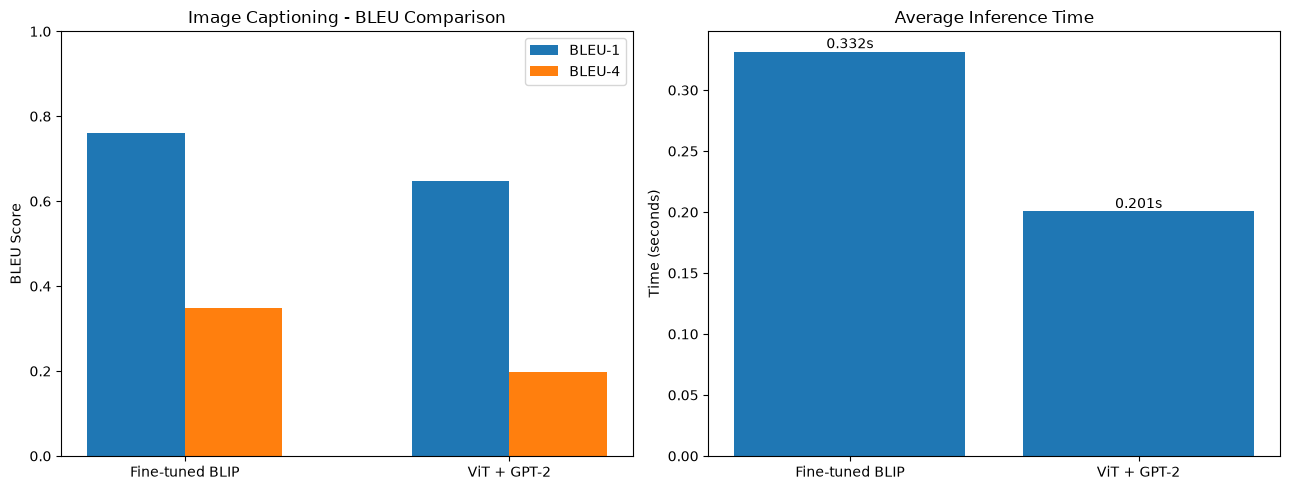

In [85]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison_df["Model"].tolist()
x = np.arange(len(models))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# BLEU 比較
width = 0.3

axes[0].bar(
    x - width / 2,
    comparison_df["BLEU-1"],
    width,
    label="BLEU-1"
)

axes[0].bar(
    x + width / 2,
    comparison_df["BLEU-4"],
    width,
    label="BLEU-4"
)

axes[0].set_title("Image Captioning - BLEU Comparison")
axes[0].set_ylabel("BLEU Score")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].set_ylim(0, 1)
axes[0].legend()

# 推論時間比較
bars = axes[1].bar(
    models,
    comparison_df["Avg Inference Time (s)"]
)

axes[1].set_title("Average Inference Time")
axes[1].set_ylabel("Time (seconds)")

for bar in bars:
    height = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.3f}s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 17. Experimental Results

### 17.1 Quantitative Evaluation

The following table presents the evaluation results on 100 Flickr30k test images.

| Metric | Fine-tuned BLIP | ViT + GPT-2 |
|---|---:|---:|
| Corpus BLEU-1 | **0.7604** | 0.6476 |
| Corpus BLEU-4 | **0.3489** | 0.1985 |
| Average Inference Time (s) | 0.3316 | **0.2006** |

Fine-tuned BLIP achieved higher BLEU-1 and BLEU-4 scores than ViT + GPT-2, indicating that its generated captions had greater n-gram overlap with the reference captions.

However, ViT + GPT-2 required less inference time, making it faster for caption generation in this experiment.

### 17.2 Gemini Evaluation

Gemini was used to evaluate whether the generated captions accurately described the content of a sample image.

**Test Image:** `1007129816.jpg`

| Model | Generated Caption | Gemini Score |
|---|---|---|
| Fine-tuned BLIP | a man wearing a hat and glasses. | 3/5 |
| ViT + GPT-2 | a man wearing a hat and glasses | 3/5 |

Gemini confirmed that both captions correctly identified the main subject and objects without hallucination.

However, both models failed to describe the distinctive design of the man's hat.

This demonstrates that even when generated captions are visually correct, they may still omit important image details.

### 17.3 Discussion

The experimental results demonstrate a trade-off between caption quality and inference speed.

Fine-tuned BLIP achieved better BLEU scores, while ViT + GPT-2 provided faster inference.

One important consideration is that BLIP was fine-tuned on Flickr30k, whereas ViT + GPT-2 used pretrained weights. Therefore, the performance difference cannot be attributed solely to model architecture.

Additionally, BLEU evaluates textual overlap with reference captions rather than directly measuring visual correctness. Gemini-based evaluation provides a complementary assessment of whether captions match the actual image content.

The Gemini evaluation was conducted on one sample image, so its score should not be interpreted as the overall performance of either model.

### 17.4 Conclusion

In this assignment, an Image Captioning model was successfully fine-tuned using the Flickr30k dataset.

Two different Image Captioning methods, Fine-tuned BLIP and ViT + GPT-2, were compared using BLEU scores and inference time.

The results showed that Fine-tuned BLIP achieved better caption quality according to BLEU, while ViT + GPT-2 generated captions more quickly.

Gemini evaluation further demonstrated that both methods could generate accurate captions but might omit important visual details.

Overall, the experiment demonstrates that Image Captioning performance should be evaluated using multiple criteria, including textual similarity, visual correctness, and computational efficiency.